In [6]:
# ============================================
# PHASE 1: DATASET UNDERSTANDING
# ============================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import os
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
pip install pandas

  Using cached pandas-3.0.5-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.2-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached tzdata-2026.3-py2.py3-none-any.whl.metadata (1.4 kB)
Using cached pandas-3.0.5-cp314-cp314-win_amd64.whl (10.0 MB)
Using cached numpy-2.5.2-cp314-cp314-win_amd64.whl (12.6 MB)
Using cached tzdata-2026.3-py2.py3-none-any.whl (348 kB)

   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/

In [3]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install matplotlib

  Using cached matplotlib-3.11.1-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.63.0-cp314-cp314-win_amd64.whl.metadata (121 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
Using cached matplotlib-3.11.1-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl (232 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.63.0-cp314-cp314-win_amd64.whl (2.3 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl (7.2 MB)
Using cached pyparsing-3.3.2-py3-none-any.whl (122 kB)

   ---------------------------------------- 0/7 [pyparsing]
   -

In [5]:
pip install seaborn 

Note: you may need to restart the kernel to use updated packages.


In [8]:
# Load dataset



df = pd.read_csv("B:\CA2 E\Laptop_Train_v2.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 2358
Number of columns: 6


In [10]:
print("Dataset shape:", df.shape)

Dataset shape: (2358, 6)


In [12]:
df.head()

,id,Sentence,Aspect Term,polarity,from,to
0,2339,I charge it at night and skip taking the cord ...,cord,neutral,41,45
1,2339,I charge it at night and skip taking the cord ...,battery life,positive,74,86
2,1316,The tech guy then said the service center does...,service center,negative,27,41
3,1316,The tech guy then said the service center does...,"""sales"" team",negative,109,121
4,1316,The tech guy then said the service center does...,tech guy,neutral,4,12


In [13]:
df.head(10)

,id,Sentence,Aspect Term,polarity,from,to
0,2339,I charge it at night and skip taking the cord ...,cord,neutral,41,45
1,2339,I charge it at night and skip taking the cord ...,battery life,positive,74,86
2,1316,The tech guy then said the service center does...,service center,negative,27,41
3,1316,The tech guy then said the service center does...,"""sales"" team",negative,109,121
4,1316,The tech guy then said the service center does...,tech guy,neutral,4,12
5,2005,"it is of high quality, has a killer GUI, is ex...",quality,positive,14,21
6,2005,"it is of high quality, has a killer GUI, is ex...",GUI,positive,36,39
7,2005,"it is of high quality, has a killer GUI, is ex...",applications,positive,118,130
8,2005,"it is of high quality, has a killer GUI, is ex...",use,positive,143,146
9,2789,Easy to start up and does not overheat as much...,start up,positive,8,16


In [14]:
df.tail()

,id,Sentence,Aspect Term,polarity,from,to
2353,2272,We also use Paralles so we can run virtual mac...,Windows Server Enterprise 2003,neutral,104,134
2354,2272,We also use Paralles so we can run virtual mac...,Windows Server 2008 Enterprise,neutral,140,170
2355,848,"How Toshiba handles the repair seems to vary, ...",repair,conflict,24,30
2356,848,"How Toshiba handles the repair seems to vary, ...",repair,positive,130,136
2357,734,I would like to use a different operating syst...,operating system,neutral,32,48


In [15]:
print("Columns in dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(i, "→", column)

Columns in dataset:

1 → id
2 → Sentence
3 → Aspect Term
4 → polarity
5 → from
6 → to


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2358 entries, 0 to 2357
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           2358 non-null   int64
 1   Sentence     2358 non-null   str  
 2   Aspect Term  2358 non-null   str  
 3   polarity     2358 non-null   str  
 4   from         2358 non-null   int64
 5   to           2358 non-null   int64
dtypes: int64(3), str(3)
memory usage: 110.7 KB


In [17]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
id             0
Sentence       0
Aspect Term    0
polarity       0
from           0
to             0
dtype: int64


In [19]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

print("Missing percentage:")
print(missing_percentage)

Missing percentage:
id             0.0
Sentence       0.0
Aspect Term    0.0
polarity       0.0
from           0.0
to             0.0
dtype: float64


In [20]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [21]:
print("Number of unique values in each column:\n")

for column in df.columns:
    print(
        f"{column}: {df[column].nunique()} unique values"
    )

Number of unique values in each column:

id: 1488 unique values
Sentence: 1482 unique values
Aspect Term: 1042 unique values
polarity: 4 unique values
from: 202 unique values
to: 202 unique values


In [22]:
print("Polarity distribution:")
print(df["polarity"].value_counts())

Polarity distribution:
polarity
positive    987
negative    866
neutral     460
conflict     45
Name: count, dtype: int64


In [23]:
print("\nPolarity percentage:")

print(
    df["polarity"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Polarity percentage:
polarity
positive    41.86
negative    36.73
neutral     19.51
conflict     1.91
Name: proportion, dtype: float64


In [24]:
print(
    "Number of unique aspect terms:",
    df["Aspect Term"].nunique()
)

Number of unique aspect terms: 1042


In [25]:
print("\nTop 20 aspect terms:")

print(
    df["Aspect Term"]
    .value_counts()
    .head(20)
)


Top 20 aspect terms:
Aspect Term
screen          58
price           55
use             53
battery life    52
battery         45
keyboard        43
programs        36
software        33
features        32
warranty        31
hard drive      30
quality         24
size            23
performance     22
speed           21
Windows         20
memory          17
graphics        17
applications    16
motherboard     15
Name: count, dtype: int64


In [27]:
df.describe(include="all")

,id,Sentence,Aspect Term,polarity,from,to
count,2358.000000,2358,2358,2358,2358.000000,2358.000000
unique,NaN,1482,1042,4,NaN,NaN
top,NaN,There are several programs for school or offic...,screen,positive,NaN,NaN
freq,NaN,13,58,987,NaN,NaN
mean,1627.559372,NaN,NaN,NaN,49.363020,58.785411
std,910.748883,NaN,NaN,NaN,44.026428,44.328897
min,3.000000,NaN,NaN,NaN,0.000000,3.000000
25%,834.250000,NaN,NaN,NaN,17.000000,26.000000
50%,1684.000000,NaN,NaN,NaN,38.000000,48.000000
75%,2446.000000,NaN,NaN,NaN,71.000000,80.000000


In [28]:
df.describe()

,id,from,to
count,2358.000000,2358.000000,2358.000000
mean,1627.559372,49.363020,58.785411
std,910.748883,44.026428,44.328897
min,3.000000,0.000000,3.000000
25%,834.250000,17.000000,26.000000
50%,1684.000000,38.000000,48.000000
75%,2446.000000,71.000000,80.000000
max,3085.000000,349.000000,356.000000


PHASE 2 — Exploratory Data Analysis

In [29]:
# ============================================
# PHASE 2: EXPLORATORY DATA ANALYSIS
# ============================================

polarity_counts = df["polarity"].value_counts()

print("Polarity Distribution:")
print(polarity_counts)

Polarity Distribution:
polarity
positive    987
negative    866
neutral     460
conflict     45
Name: count, dtype: int64


In [30]:
# ============================================
# PHASE 2: EXPLORATORY DATA ANALYSIS
# ============================================

polarity_counts = df["polarity"].value_counts()

print("Polarity Distribution:")
print(polarity_counts)

Polarity Distribution:
polarity
positive    987
negative    866
neutral     460
conflict     45
Name: count, dtype: int64


In [31]:
polarity_percentage = (
    df["polarity"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Polarity Percentage:")
print(polarity_percentage)

Polarity Percentage:
polarity
positive    41.86
negative    36.73
neutral     19.51
conflict     1.91
Name: proportion, dtype: float64


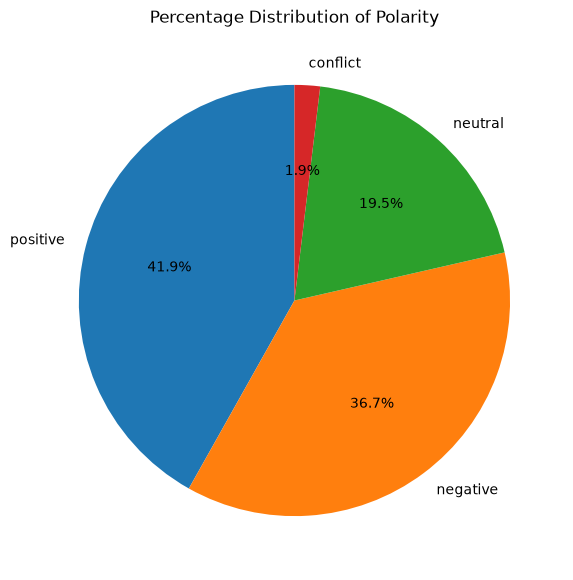

In [33]:
plt.figure(figsize=(7, 7))

plt.pie(
    polarity_percentage.values,
    labels=polarity_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Polarity")

plt.show()

In [34]:
aspect_counts = (
    df["Aspect Term"]
    .value_counts()
    .head(20)
)

print("Top 20 Product Aspects:")
print(aspect_counts)

Top 20 Product Aspects:
Aspect Term
screen          58
price           55
use             53
battery life    52
battery         45
keyboard        43
programs        36
software        33
features        32
warranty        31
hard drive      30
quality         24
size            23
performance     22
speed           21
Windows         20
memory          17
graphics        17
applications    16
motherboard     15
Name: count, dtype: int64


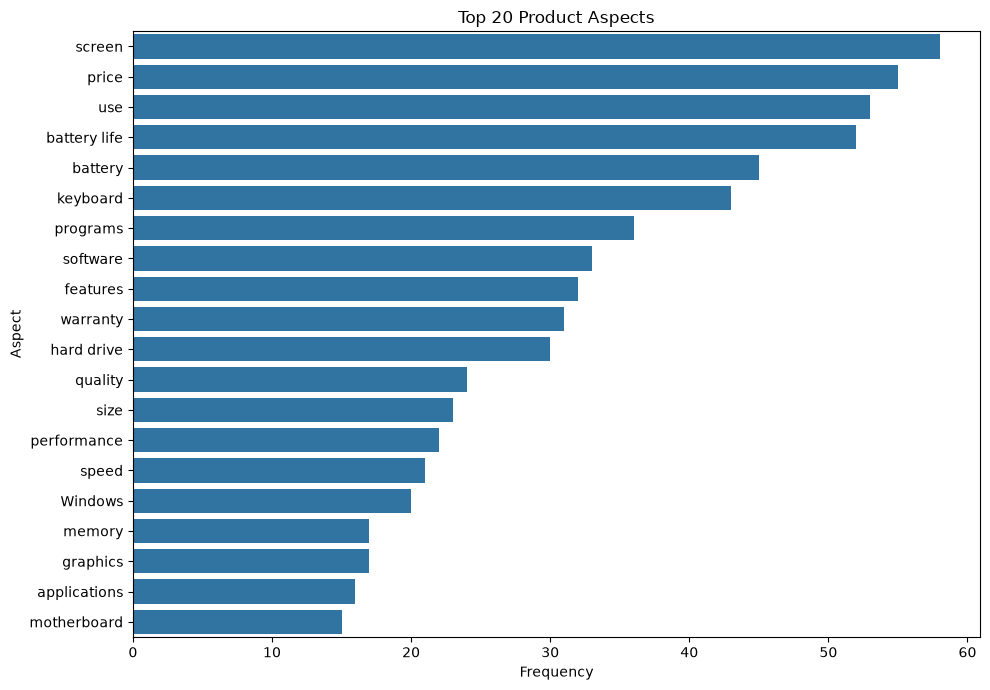

In [35]:
plt.figure(figsize=(10, 7))

sns.barplot(
    x=aspect_counts.values,
    y=aspect_counts.index
)

plt.title("Top 20 Product Aspects")
plt.xlabel("Frequency")
plt.ylabel("Aspect")

plt.tight_layout()
plt.show()

In [36]:
top_10_aspects = (
    df["Aspect Term"]
    .value_counts()
    .head(10)
)

print(top_10_aspects)

Aspect Term
screen          58
price           55
use             53
battery life    52
battery         45
keyboard        43
programs        36
software        33
features        32
warranty        31
Name: count, dtype: int64


In [38]:
aspect_polarity = pd.crosstab(
    df["Aspect Term"],
    df["polarity"]
)

aspect_polarity.head(20)

polarity,conflict,negative,neutral,positive
Aspect Term,,,,
"""sales"" team",0,1,0,0
1 GB ram,0,0,1,0
1-year-warranty,0,0,1,0
10-key,0,0,0,1
12 cell battery,0,0,0,1
13 inch,0,0,0,1
15 inch,0,0,0,1
"15""",0,0,1,0
16GB RAM support,0,0,1,0


In [39]:
top_aspects = (
    df["Aspect Term"]
    .value_counts()
    .head(15)
    .index
)

aspect_polarity_top = pd.crosstab(
    df[
        df["Aspect Term"].isin(top_aspects)
    ]["Aspect Term"],

    df[
        df["Aspect Term"].isin(top_aspects)
    ]["polarity"]
)

aspect_polarity_top

polarity,conflict,negative,neutral,positive
Aspect Term,,,,
battery,1,30,4,10
battery life,3,15,3,31
features,0,4,6,22
hard drive,0,16,11,3
keyboard,2,15,8,18
performance,0,6,3,13
price,2,7,2,44
programs,0,8,9,19
quality,2,7,0,15


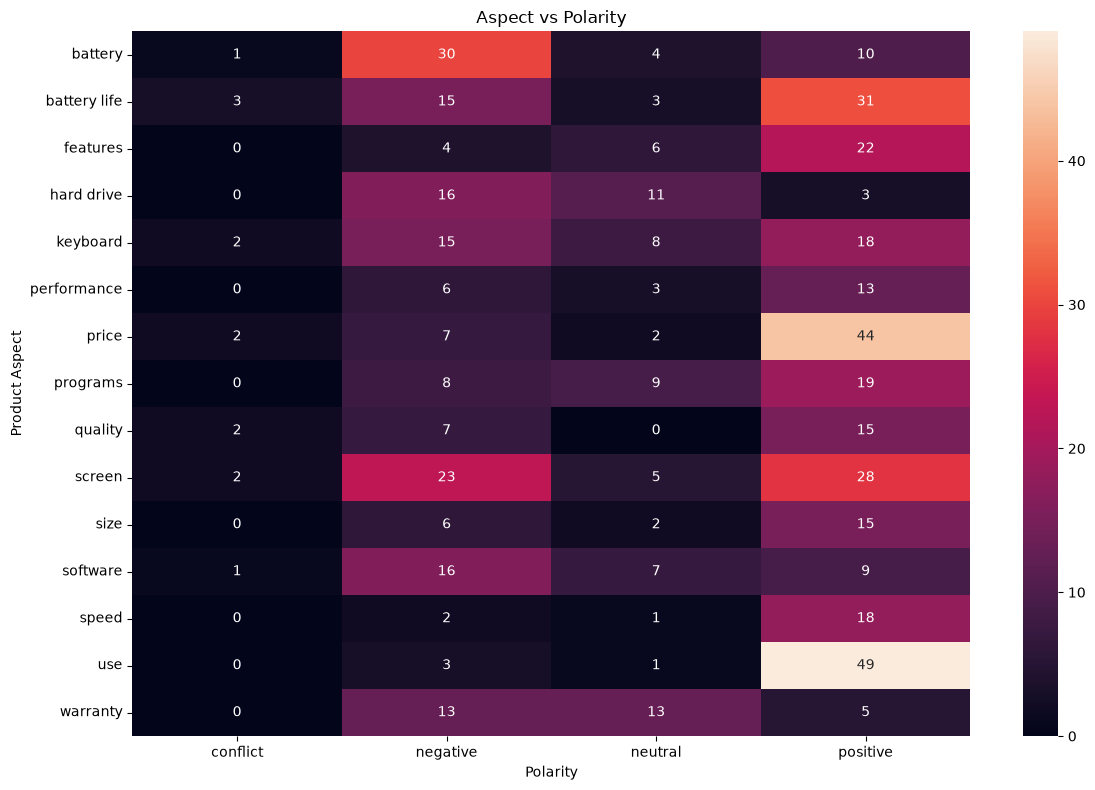

In [40]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    aspect_polarity_top,
    annot=True,
    fmt="d"
)

plt.title("Aspect vs Polarity")
plt.xlabel("Polarity")
plt.ylabel("Product Aspect")

plt.tight_layout()
plt.show()

In [41]:
df["Review Length"] = df["Sentence"].astype(str).apply(
    len
)

print(df["Review Length"].describe())

count    2358.000000
mean      104.890585
std        56.977244
min        11.000000
25%        63.000000
50%        95.000000
75%       135.000000
max       464.000000
Name: Review Length, dtype: float64


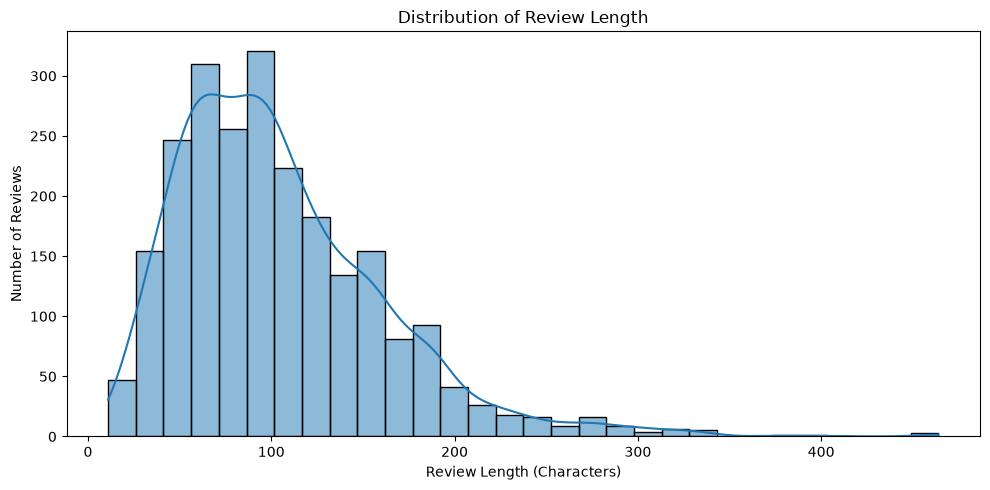

In [42]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Review Length"],
    bins=30,
    kde=True
)

plt.title("Distribution of Review Length")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

In [43]:
df["Word Count"] = (
    df["Sentence"]
    .astype(str)
    .apply(lambda x: len(x.split()))
)

print(
    df["Word Count"].describe()
)

count    2358.000000
mean       19.315522
std        10.620168
min         2.000000
25%        12.000000
50%        17.000000
75%        25.000000
max        78.000000
Name: Word Count, dtype: float64


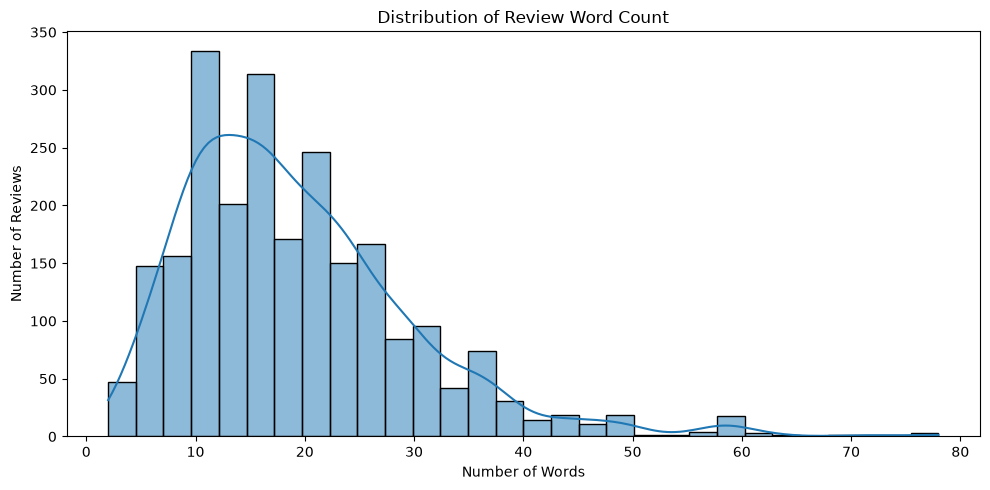

In [44]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Word Count"],
    bins=30,
    kde=True
)

plt.title("Distribution of Review Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

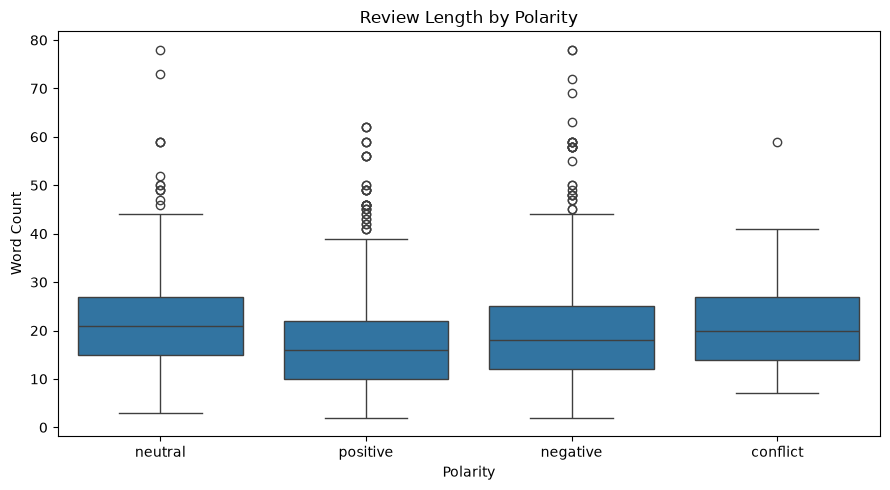

In [45]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="polarity",
    y="Word Count"
)

plt.title("Review Length by Polarity")
plt.xlabel("Polarity")
plt.ylabel("Word Count")

plt.tight_layout()
plt.show()

In [50]:
positive_aspects = (
    df[df["polarity"] == "positive"]["Aspect Term"]
    .value_counts()
    .head(10)
)

negative_aspects = (
    df[df["polarity"] == "negative"]["Aspect Term"]
    .value_counts()
    .head(10)
)

print("Top Positive Aspects:")
print(positive_aspects)

print("\nTop Negative Aspects:")
print(negative_aspects)

Top Positive Aspects:
Aspect Term
use             49
price           44
battery life    31
screen          28
features        22
programs        19
speed           18
keyboard        18
quality         15
size            15
Name: count, dtype: int64

Top Negative Aspects:
Aspect Term
battery         30
screen          23
hard drive      16
software        16
keyboard        15
battery life    15
warranty        13
Vista           12
Windows         12
motherboard     10
Name: count, dtype: int64


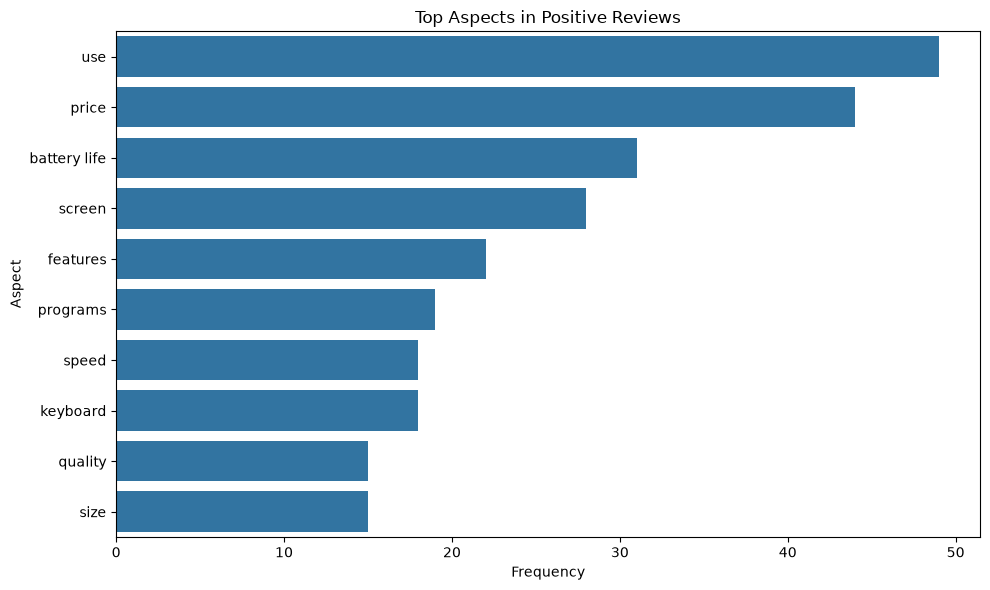

In [51]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=positive_aspects.values,
    y=positive_aspects.index
)

plt.title("Top Aspects in Positive Reviews")
plt.xlabel("Frequency")
plt.ylabel("Aspect")

plt.tight_layout()
plt.show()

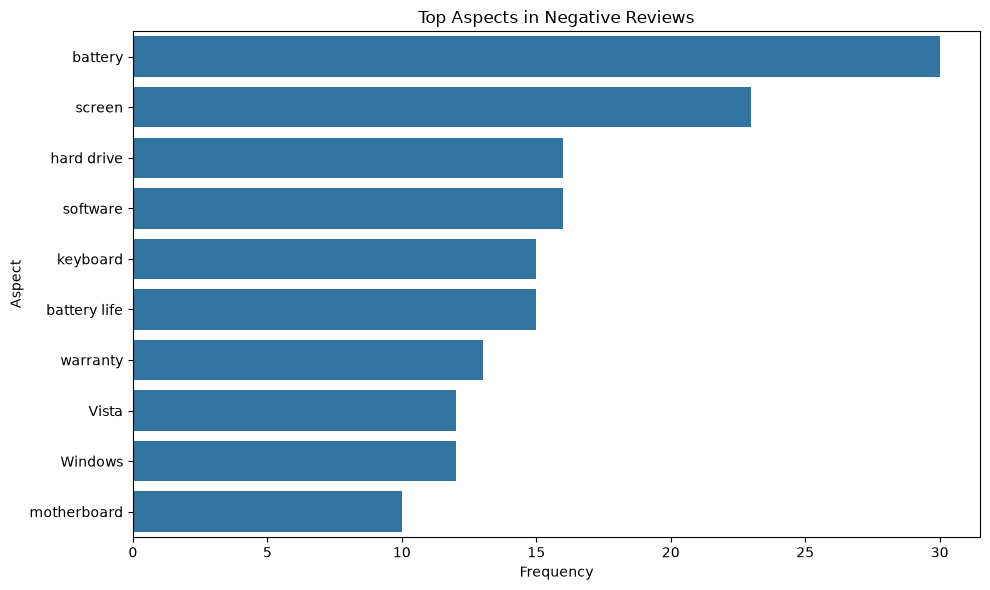

In [52]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=negative_aspects.values,
    y=negative_aspects.index
)

plt.title("Top Aspects in Negative Reviews")
plt.xlabel("Frequency")
plt.ylabel("Aspect")

plt.tight_layout()
plt.show()

In [53]:
pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


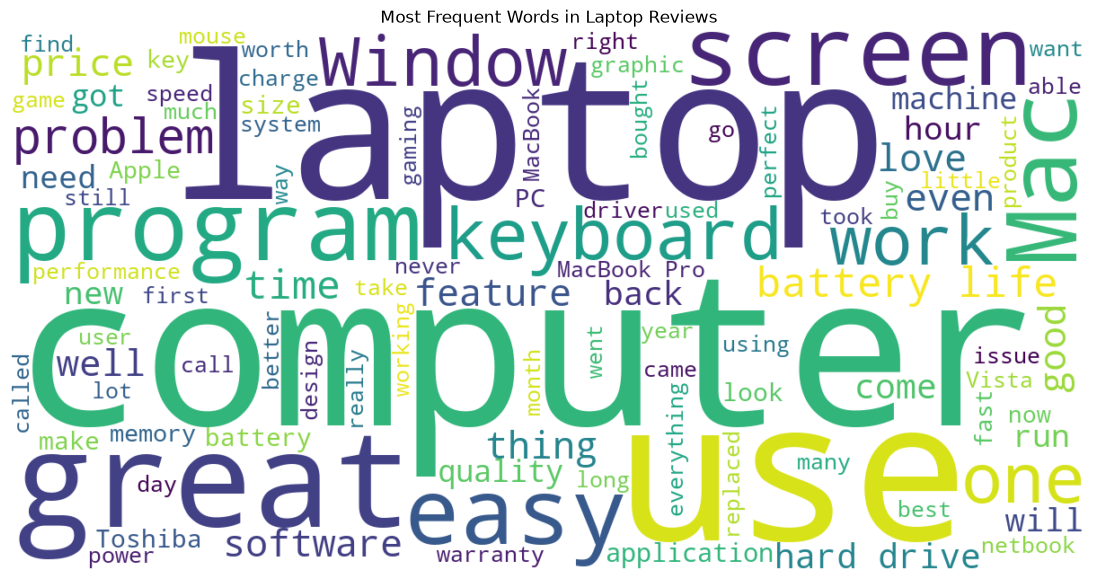

In [54]:
from wordcloud import WordCloud

text = " ".join(
    df["Sentence"]
    .astype(str)
)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(text)

plt.figure(figsize=(14, 7))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Most Frequent Words in Laptop Reviews")

plt.show()

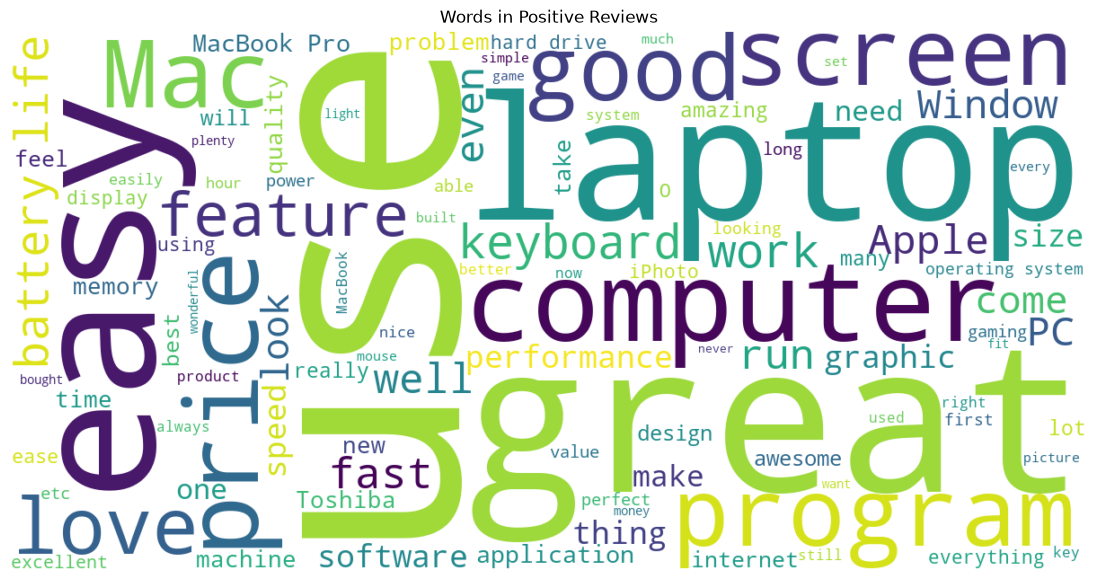

In [55]:
positive_text = " ".join(
    df[
        df["polarity"] == "positive"
    ]["Sentence"]
    .astype(str)
)

positive_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(positive_text)

plt.figure(figsize=(14, 7))

plt.imshow(
    positive_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Words in Positive Reviews")

plt.show()

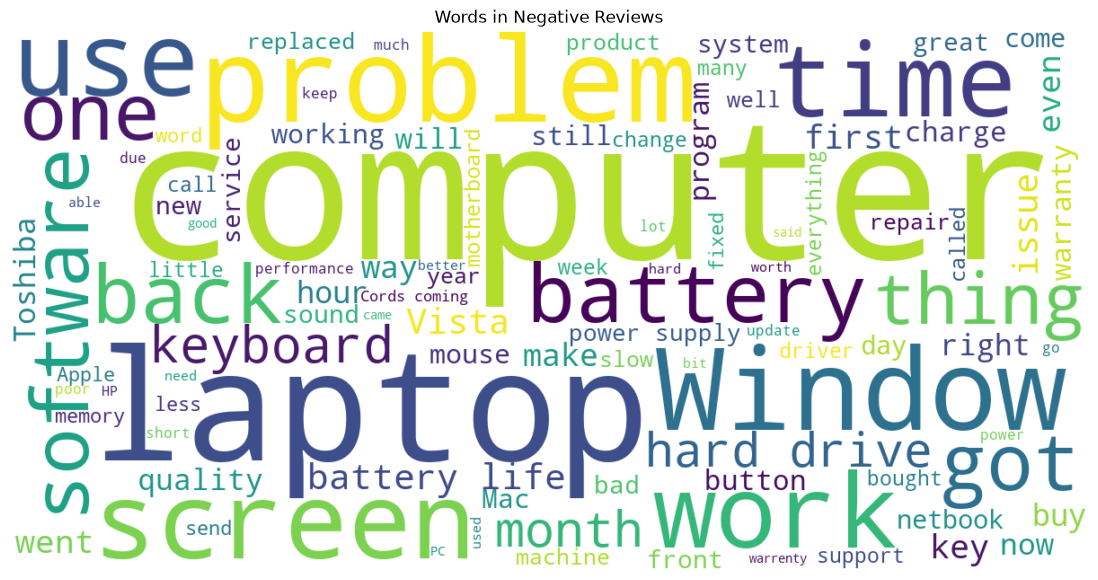

In [56]:
negative_text = " ".join(
    df[
        df["polarity"] == "negative"
    ]["Sentence"]
    .astype(str)
)

negative_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(negative_text)

plt.figure(figsize=(14, 7))

plt.imshow(
    negative_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Words in Negative Reviews")

plt.show()

In [57]:
print("=" * 60)
print("EDA SUMMARY")
print("=" * 60)

print("\nDataset Shape:")
print(df.shape)

print("\nPolarity:")
print(df["polarity"].value_counts())

print("\nTop 10 Aspects:")
print(df["Aspect Term"].value_counts().head(10))

print("\nAverage Word Count:")
print(round(df["Word Count"].mean(), 2))

print("\nAverage Review Length:")
print(round(df["Review Length"].mean(), 2))

EDA SUMMARY

Dataset Shape:
(2358, 8)

Polarity:
polarity
positive    987
negative    866
neutral     460
conflict     45
Name: count, dtype: int64

Top 10 Aspects:
Aspect Term
screen          58
price           55
use             53
battery life    52
battery         45
keyboard        43
programs        36
software        33
features        32
warranty        31
Name: count, dtype: int64

Average Word Count:
19.32

Average Review Length:
104.89


In [58]:
# ============================================
# PHASE 3: DATA CLEANING
# ============================================

clean_df = df.copy()

print("Original dataset shape:", clean_df.shape)

Original dataset shape: (2358, 8)


In [59]:
print("Missing values before cleaning:")
print(clean_df.isnull().sum())

Missing values before cleaning:
id               0
Sentence         0
Aspect Term      0
polarity         0
from             0
to               0
Review Length    0
Word Count       0
dtype: int64


In [60]:
missing_percentage = (
    clean_df.isnull().sum()
    / len(clean_df)
    * 100
).round(2)

print("\nMissing value percentage:")
print(missing_percentage)


Missing value percentage:
id               0.0
Sentence         0.0
Aspect Term      0.0
polarity         0.0
from             0.0
to               0.0
Review Length    0.0
Word Count       0.0
dtype: float64


In [61]:
duplicate_count = clean_df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


In [62]:
clean_df = clean_df.drop_duplicates()

print("Shape after removing duplicates:")
print(clean_df.shape)

Shape after removing duplicates:
(2358, 8)


In [63]:
required_columns = [
    "Sentence",
    "Aspect Term",
    "polarity"
]

clean_df = clean_df.dropna(
    subset=required_columns
)

print(
    "Shape after removing missing required values:",
    clean_df.shape
)

Shape after removing missing required values: (2358, 8)


In [64]:
empty_sentences = (
    clean_df["Sentence"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

empty_aspects = (
    clean_df["Aspect Term"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()

)

print("Empty sentences:", empty_sentences)
print("Empty aspect terms:", empty_aspects)

Empty sentences: 0
Empty aspect terms: 0


In [65]:
clean_df = clean_df[
    (clean_df["Sentence"].astype(str).str.strip() != "") &
    (clean_df["Aspect Term"].astype(str).str.strip() != "")
]

print("Shape after removing empty values:")
print(clean_df.shape)

Shape after removing empty values:
(2358, 8)


In [66]:
def clean_text(text):

    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(
        r"<.*?>",
        " ",
        text
    )

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+",
        " ",
        text
    )

    # Remove extra whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    # Remove leading/trailing spaces
    text = text.strip()

    return text

In [67]:
clean_df["Clean Sentence"] = (
    clean_df["Sentence"]
    .apply(clean_text)
)

In [68]:
clean_df["Clean Aspect"] = (
    clean_df["Aspect Term"]
    .apply(clean_text)
)

In [69]:
clean_df[
    [
        "Sentence",
        "Clean Sentence",
        "Aspect Term",
        "Clean Aspect"
    ]
].head(10)

,Sentence,Clean Sentence,Aspect Term,Clean Aspect
0,I charge it at night and skip taking the cord ...,i charge it at night and skip taking the cord ...,cord,cord
1,I charge it at night and skip taking the cord ...,i charge it at night and skip taking the cord ...,battery life,battery life
2,The tech guy then said the service center does...,the tech guy then said the service center does...,service center,service center
3,The tech guy then said the service center does...,the tech guy then said the service center does...,"""sales"" team","""sales"" team"
4,The tech guy then said the service center does...,the tech guy then said the service center does...,tech guy,tech guy
5,"it is of high quality, has a killer GUI, is ex...","it is of high quality, has a killer gui, is ex...",quality,quality
6,"it is of high quality, has a killer GUI, is ex...","it is of high quality, has a killer gui, is ex...",GUI,gui
7,"it is of high quality, has a killer GUI, is ex...","it is of high quality, has a killer gui, is ex...",applications,applications
8,"it is of high quality, has a killer GUI, is ex...","it is of high quality, has a killer gui, is ex...",use,use
9,Easy to start up and does not overheat as much...,easy to start up and does not overheat as much...,start up,start up


In [70]:
def remove_special_characters(text):

    text = str(text)

    # Keep alphabetic characters and spaces
    text = re.sub(
        r"[^a-zA-Z\s]",
        " ",
        text
    )

    # Remove multiple spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()

In [71]:
clean_df["Clean Sentence"] = (
    clean_df["Clean Sentence"]
    .apply(remove_special_characters)
)

clean_df["Clean Aspect"] = (
    clean_df["Clean Aspect"]
    .apply(remove_special_characters)
)

In [72]:
clean_df[
    [
        "Sentence",
        "Clean Sentence",
        "Aspect Term",
        "Clean Aspect"
    ]
].head(10)

,Sentence,Clean Sentence,Aspect Term,Clean Aspect
0,I charge it at night and skip taking the cord ...,i charge it at night and skip taking the cord ...,cord,cord
1,I charge it at night and skip taking the cord ...,i charge it at night and skip taking the cord ...,battery life,battery life
2,The tech guy then said the service center does...,the tech guy then said the service center does...,service center,service center
3,The tech guy then said the service center does...,the tech guy then said the service center does...,"""sales"" team",sales team
4,The tech guy then said the service center does...,the tech guy then said the service center does...,tech guy,tech guy
5,"it is of high quality, has a killer GUI, is ex...",it is of high quality has a killer gui is extr...,quality,quality
6,"it is of high quality, has a killer GUI, is ex...",it is of high quality has a killer gui is extr...,GUI,gui
7,"it is of high quality, has a killer GUI, is ex...",it is of high quality has a killer gui is extr...,applications,applications
8,"it is of high quality, has a killer GUI, is ex...",it is of high quality has a killer gui is extr...,use,use
9,Easy to start up and does not overheat as much...,easy to start up and does not overheat as much...,start up,start up


In [73]:
print(
    clean_df["polarity"]
    .value_counts()
)

polarity
positive    987
negative    866
neutral     460
conflict     45
Name: count, dtype: int64


In [74]:
clean_df["polarity"] = (
    clean_df["polarity"]
    .astype(str)
    .str.lower()
    .str.strip()
)

In [75]:
print(
    clean_df["polarity"]
    .value_counts()
)

polarity
positive    987
negative    866
neutral     460
conflict     45
Name: count, dtype: int64


In [76]:
valid_polarities = [
    "positive",
    "negative",
    "neutral",
    "conflict"
]

invalid_polarity = clean_df[
    ~clean_df["polarity"].isin(valid_polarities)
]

print(
    "Invalid polarity records:",
    len(invalid_polarity)
)

Invalid polarity records: 0


In [77]:
clean_df = clean_df[
    clean_df["polarity"].isin(valid_polarities)
]

print(
    "Dataset shape:",
    clean_df.shape
)

Dataset shape: (2358, 10)


In [78]:
clean_df["Text Length"] = (
    clean_df["Clean Sentence"]
    .str.len()
)

print(
    clean_df["Text Length"].describe()
)

count    2358.000000
mean      101.576760
std        55.564453
min        10.000000
25%        61.000000
50%        92.000000
75%       130.750000
max       460.000000
Name: Text Length, dtype: float64


In [79]:
print(
    clean_df[
        clean_df["Text Length"] < 3
    ][
        [
            "Sentence",
            "Clean Sentence"
        ]
    ]
)

Empty DataFrame
Columns: [Sentence, Clean Sentence]
Index: []


In [80]:
clean_df = clean_df[
    clean_df["Text Length"] >= 3
]

In [81]:
print("=" * 60)
print("MISSING VALUES AFTER CLEANING")
print("=" * 60)

print(
    clean_df.isnull().sum()
)

MISSING VALUES AFTER CLEANING
id                0
Sentence          0
Aspect Term       0
polarity          0
from              0
to                0
Review Length     0
Word Count        0
Clean Sentence    0
Clean Aspect      0
Text Length       0
dtype: int64


In [82]:
print("=" * 60)
print("CLEAN DATASET INFORMATION")
print("=" * 60)

print(
    clean_df.info()
)

CLEAN DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 2358 entries, 0 to 2357
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              2358 non-null   int64
 1   Sentence        2358 non-null   str  
 2   Aspect Term     2358 non-null   str  
 3   polarity        2358 non-null   str  
 4   from            2358 non-null   int64
 5   to              2358 non-null   int64
 6   Review Length   2358 non-null   int64
 7   Word Count      2358 non-null   int64
 8   Clean Sentence  2358 non-null   str  
 9   Clean Aspect    2358 non-null   str  
 10  Text Length     2358 non-null   int64
dtypes: int64(6), str(5)
memory usage: 202.8 KB
None


In [83]:
print("Original dataset rows:", len(df))
print("Cleaned dataset rows:", len(clean_df))

removed_rows = len(df) - len(clean_df)

print(
    "Rows removed:",
    removed_rows
)

print(
    "Percentage removed:",
    round(
        removed_rows / len(df) * 100,
        2
    ),
    "%"
)

Original dataset rows: 2358
Cleaned dataset rows: 2358
Rows removed: 0
Percentage removed: 0.0 %


In [84]:
print("Original polarity distribution:")
print(
    df["polarity"].value_counts()
)

print("\nCleaned polarity distribution:")
print(
    clean_df["polarity"].value_counts()
)

Original polarity distribution:
polarity
positive    987
negative    866
neutral     460
conflict     45
Name: count, dtype: int64

Cleaned polarity distribution:
polarity
positive    987
negative    866
neutral     460
conflict     45
Name: count, dtype: int64


In [85]:
clean_df.head(10)

,id,Sentence,Aspect Term,polarity,from,to,Review Length,Word Count,Clean Sentence,Clean Aspect,Text Length
0,2339,I charge it at night and skip taking the cord ...,cord,neutral,41,45,87,18,i charge it at night and skip taking the cord ...,cord,86
1,2339,I charge it at night and skip taking the cord ...,battery life,positive,74,86,87,18,i charge it at night and skip taking the cord ...,battery life,86
2,1316,The tech guy then said the service center does...,service center,negative,27,41,179,35,the tech guy then said the service center does...,service center,171
3,1316,The tech guy then said the service center does...,"""sales"" team",negative,109,121,179,35,the tech guy then said the service center does...,sales team,171
4,1316,The tech guy then said the service center does...,tech guy,neutral,4,12,179,35,the tech guy then said the service center does...,tech guy,171
5,2005,"it is of high quality, has a killer GUI, is ex...",quality,positive,14,21,175,31,it is of high quality has a killer gui is extr...,quality,168
6,2005,"it is of high quality, has a killer GUI, is ex...",GUI,positive,36,39,175,31,it is of high quality has a killer gui is extr...,gui,168
7,2005,"it is of high quality, has a killer GUI, is ex...",applications,positive,118,130,175,31,it is of high quality has a killer gui is extr...,applications,168
8,2005,"it is of high quality, has a killer GUI, is ex...",use,positive,143,146,175,31,it is of high quality has a killer gui is extr...,use,168
9,2789,Easy to start up and does not overheat as much...,start up,positive,8,16,64,13,easy to start up and does not overheat as much...,start up,63


In [86]:
clean_df.to_csv(
    "cleaned_laptop_reviews.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Cleaned dataset saved successfully!"
)

print(
    "File: cleaned_laptop_reviews.csv"
)

Cleaned dataset saved successfully!
File: cleaned_laptop_reviews.csv


In [87]:
clean_df.to_csv(
    "cleaned_laptop_reviews.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Cleaned dataset saved successfully!"
)

print(
    "File: cleaned_laptop_reviews.csv"
)

Cleaned dataset saved successfully!
File: cleaned_laptop_reviews.csv


In [90]:
# ============================================
# PHASE 4: TEXT PREPROCESSING
# ============================================

import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

print("NLTK imported successfully!")

NLTK imported successfully!


In [89]:
pip install nltk

  Using cached nltk-3.10.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached regex-2026.7.19-cp314-cp314-win_amd64.whl.metadata (41 kB)
  Using cached tqdm-4.70.0-py3-none-any.whl.metadata (57 kB)
Using cached nltk-3.10.3-py3-none-any.whl (1.8 MB)
Using cached regex-2026.7.19-cp314-cp314-win_amd64.whl (280 kB)
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached defusedxml-0.7.1-py2.py3-none-any.whl (25 kB)
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
Using cached tqdm-4.70.0-py3-none-any.whl (80 kB)

   ------ --------------------------------- 1/6 [regex]
   ------------- -------------------------- 2/6 [joblib]
   ------------- -------------------------- 2/6 [joblib]
   --------------------------------- ------ 5/6 [nltk]
   --------------------------------- ------ 5/6 [nltk]


In [91]:
# Download required NLTK resources

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("NLTK resources downloaded successfully!")

NLTK resources downloaded successfully!


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ritik\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ritik\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ritik\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ritik\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\ritik\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [92]:
print("Clean dataset shape:", clean_df.shape)

clean_df.head()

Clean dataset shape: (2358, 11)


,id,Sentence,Aspect Term,polarity,from,to,Review Length,Word Count,Clean Sentence,Clean Aspect,Text Length
0,2339,I charge it at night and skip taking the cord ...,cord,neutral,41,45,87,18,i charge it at night and skip taking the cord ...,cord,86
1,2339,I charge it at night and skip taking the cord ...,battery life,positive,74,86,87,18,i charge it at night and skip taking the cord ...,battery life,86
2,1316,The tech guy then said the service center does...,service center,negative,27,41,179,35,the tech guy then said the service center does...,service center,171
3,1316,The tech guy then said the service center does...,"""sales"" team",negative,109,121,179,35,the tech guy then said the service center does...,sales team,171
4,1316,The tech guy then said the service center does...,tech guy,neutral,4,12,179,35,the tech guy then said the service center does...,tech guy,171


In [93]:
# Get English stopwords

stop_words = set(
    stopwords.words("english")
)

# Important words that should NOT be removed
important_words = {
    "not",
    "no",
    "never",
    "neither",
    "nor",
    "nothing",
    "hardly",
    "barely"
}

stop_words = stop_words - important_words

print(
    "Number of stopwords:",
    len(stop_words)
)

print(
    "\nPreserved words:",
    important_words
)

Number of stopwords: 195

Preserved words: {'nothing', 'never', 'neither', 'hardly', 'barely', 'not', 'no', 'nor'}


In [94]:
lemmatizer = WordNetLemmatizer()

print("Lemmatizer created successfully!")

Lemmatizer created successfully!


In [95]:
def preprocess_text(text):

    # Convert to string
    text = str(text)

    # Lowercase
    text = text.lower()

    # Remove special characters
    text = re.sub(
        r"[^a-zA-Z\s]",
        " ",
        text
    )

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal + lemmatization
    processed_tokens = []

    for word in tokens:

        # Keep words that are not stopwords
        if word not in stop_words:

            # Ignore very short words
            if len(word) > 1:

                lemma = lemmatizer.lemmatize(word)

                processed_tokens.append(
                    lemma
                )

    # Convert tokens back to text
    processed_text = " ".join(
        processed_tokens
    )

    return processed_text

In [96]:
test_text = """
I am not happy with the battery.
The battery drains very quickly and
the laptop becomes extremely hot.
"""

print("Original:")
print(test_text)

print("\nProcessed:")
print(
    preprocess_text(test_text)
)

Original:

I am not happy with the battery.
The battery drains very quickly and
the laptop becomes extremely hot.


Processed:
not happy battery battery drain quickly laptop becomes extremely hot


In [97]:
print("Processing review text...")

clean_df["Processed Text"] = (
    clean_df["Clean Sentence"]
    .apply(preprocess_text)
)

print("Review preprocessing completed!")

Processing review text...
Review preprocessing completed!


In [98]:
clean_df["Processed Aspect"] = (
    clean_df["Clean Aspect"]
    .apply(preprocess_text)
)

print("Aspect preprocessing completed!")

Aspect preprocessing completed!


In [99]:
comparison = clean_df[
    [
        "Sentence",
        "Clean Sentence",
        "Processed Text",
        "Aspect Term",
        "Processed Aspect"
    ]
].head(10)

comparison

,Sentence,Clean Sentence,Processed Text,Aspect Term,Processed Aspect
0,I charge it at night and skip taking the cord ...,i charge it at night and skip taking the cord ...,charge night skip taking cord good battery life,cord,cord
1,I charge it at night and skip taking the cord ...,i charge it at night and skip taking the cord ...,charge night skip taking cord good battery life,battery life,battery life
2,The tech guy then said the service center does...,the tech guy then said the service center does...,tech guy said service center not exchange dire...,service center,service center
3,The tech guy then said the service center does...,the tech guy then said the service center does...,tech guy said service center not exchange dire...,"""sales"" team",sale team
4,The tech guy then said the service center does...,the tech guy then said the service center does...,tech guy said service center not exchange dire...,tech guy,tech guy
5,"it is of high quality, has a killer GUI, is ex...",it is of high quality has a killer gui is extr...,high quality killer gui extremely stable highl...,quality,quality
6,"it is of high quality, has a killer GUI, is ex...",it is of high quality has a killer gui is extr...,high quality killer gui extremely stable highl...,GUI,gui
7,"it is of high quality, has a killer GUI, is ex...",it is of high quality has a killer gui is extr...,high quality killer gui extremely stable highl...,applications,application
8,"it is of high quality, has a killer GUI, is ex...",it is of high quality has a killer gui is extr...,high quality killer gui extremely stable highl...,use,use
9,Easy to start up and does not overheat as much...,easy to start up and does not overheat as much...,easy start not overheat much laptop,start up,start


In [100]:
empty_processed = (
    clean_df["Processed Text"]
    .str.strip()
    .eq("")
    .sum()
)

print(
    "Empty processed reviews:",
    empty_processed
)

Empty processed reviews: 0


In [101]:
clean_df = clean_df[
    clean_df["Processed Text"]
    .str.strip()
    .ne("")
]

clean_df = clean_df[
    clean_df["Processed Aspect"]
    .str.strip()
    .ne("")
]

print(
    "Dataset shape after preprocessing:",
    clean_df.shape
)

Dataset shape after preprocessing: (2354, 13)


In [102]:
clean_df["Model Text"] = (
    clean_df["Processed Text"]
    + " aspect "
    + clean_df["Processed Aspect"]
)

In [103]:
clean_df[
    [
        "Processed Text",
        "Processed Aspect",
        "Model Text"
    ]
].head(10)

,Processed Text,Processed Aspect,Model Text
0,charge night skip taking cord good battery life,cord,charge night skip taking cord good battery lif...
1,charge night skip taking cord good battery life,battery life,charge night skip taking cord good battery lif...
2,tech guy said service center not exchange dire...,service center,tech guy said service center not exchange dire...
3,tech guy said service center not exchange dire...,sale team,tech guy said service center not exchange dire...
4,tech guy said service center not exchange dire...,tech guy,tech guy said service center not exchange dire...
5,high quality killer gui extremely stable highl...,quality,high quality killer gui extremely stable highl...
6,high quality killer gui extremely stable highl...,gui,high quality killer gui extremely stable highl...
7,high quality killer gui extremely stable highl...,application,high quality killer gui extremely stable highl...
8,high quality killer gui extremely stable highl...,use,high quality killer gui extremely stable highl...
9,easy start not overheat much laptop,start,easy start not overheat much laptop aspect start


In [105]:
clean_df["Processed Word Count"] = (
    clean_df["Processed Text"]
    .apply(lambda x: len(x.split()))
)

print(
    clean_df[
        "Processed Word Count"
    ].describe()
)

count    2354.000000
mean        9.972812
std         5.310994
min         2.000000
25%         6.000000
50%         9.000000
75%        13.000000
max        36.000000
Name: Processed Word Count, dtype: float64


In [106]:
print(
    "Average original word count:",
    round(
        clean_df["Word Count"].mean(),
        2
    )
)

print(
    "Average processed word count:",
    round(
        clean_df["Processed Word Count"].mean(),
        2
    )
)

Average original word count: 19.32
Average processed word count: 9.97


In [107]:
from collections import Counter

all_words = []

for text in clean_df["Processed Text"]:

    all_words.extend(
        text.split()
    )

word_frequency = Counter(
    all_words
)

print(
    "Top 30 processed words:"
)

print(
    word_frequency.most_common(30)
)

Top 30 processed words:
[('not', 297), ('computer', 283), ('use', 261), ('laptop', 251), ('battery', 203), ('window', 203), ('great', 200), ('screen', 194), ('program', 160), ('mac', 146), ('keyboard', 142), ('would', 142), ('like', 137), ('life', 136), ('easy', 129), ('software', 129), ('also', 129), ('work', 127), ('price', 122), ('one', 119), ('time', 118), ('get', 117), ('problem', 117), ('hard', 116), ('drive', 115), ('run', 111), ('even', 108), ('no', 108), ('feature', 104), ('good', 99)]


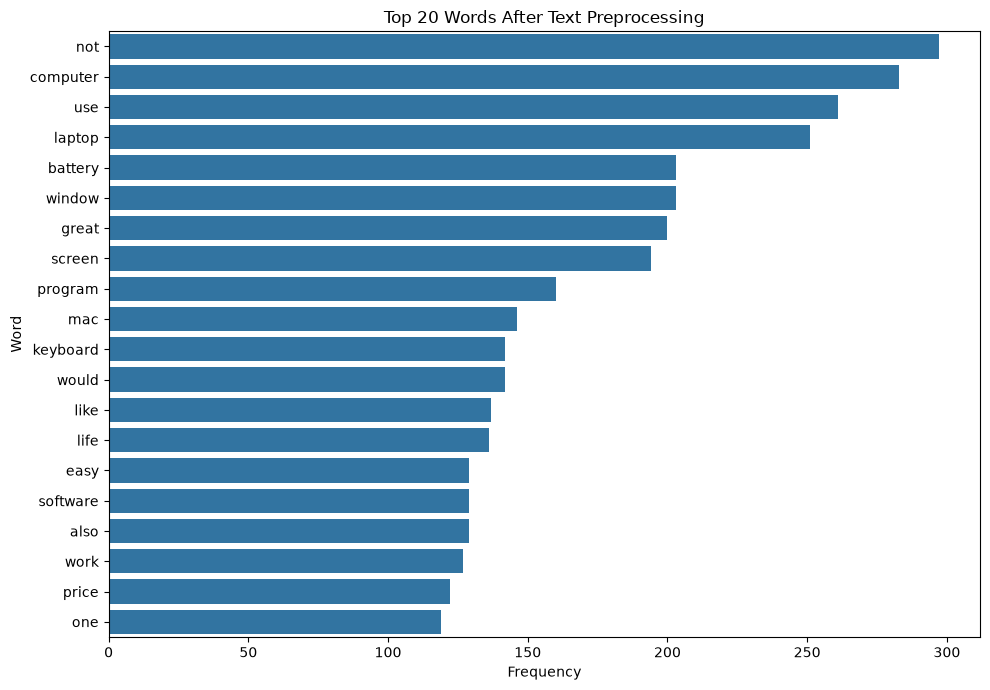

In [108]:
top_words = pd.DataFrame(
    word_frequency.most_common(20),
    columns=[
        "Word",
        "Frequency"
    ]
)

plt.figure(
    figsize=(10, 7)
)

sns.barplot(
    data=top_words,
    x="Frequency",
    y="Word"
)

plt.title(
    "Top 20 Words After Text Preprocessing"
)

plt.xlabel(
    "Frequency"
)

plt.ylabel(
    "Word"
)

plt.tight_layout()

plt.show()

In [109]:
clean_df.to_csv(
    "preprocessed_laptop_reviews.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Preprocessed dataset saved successfully!"
)

print(
    "File: preprocessed_laptop_reviews.csv"
)

Preprocessed dataset saved successfully!
File: preprocessed_laptop_reviews.csv


In [110]:
# ============================================
# PHASE 5: ASPECT EXTRACTION & CATEGORIZATION
# ============================================

aspect_df = pd.read_csv(
    "preprocessed_laptop_reviews.csv"
)

print("Dataset shape:", aspect_df.shape)

aspect_df.head()

Dataset shape: (2354, 15)


,id,Sentence,Aspect Term,polarity,from,to,Review Length,Word Count,Clean Sentence,Clean Aspect,Text Length,Processed Text,Processed Aspect,Model Text,Processed Word Count
0,2339,I charge it at night and skip taking the cord ...,cord,neutral,41,45,87,18,i charge it at night and skip taking the cord ...,cord,86,charge night skip taking cord good battery life,cord,charge night skip taking cord good battery lif...,8
1,2339,I charge it at night and skip taking the cord ...,battery life,positive,74,86,87,18,i charge it at night and skip taking the cord ...,battery life,86,charge night skip taking cord good battery life,battery life,charge night skip taking cord good battery lif...,8
2,1316,The tech guy then said the service center does...,service center,negative,27,41,179,35,the tech guy then said the service center does...,service center,171,tech guy said service center not exchange dire...,service center,tech guy said service center not exchange dire...,15
3,1316,The tech guy then said the service center does...,"""sales"" team",negative,109,121,179,35,the tech guy then said the service center does...,sales team,171,tech guy said service center not exchange dire...,sale team,tech guy said service center not exchange dire...,15
4,1316,The tech guy then said the service center does...,tech guy,neutral,4,12,179,35,the tech guy then said the service center does...,tech guy,171,tech guy said service center not exchange dire...,tech guy,tech guy said service center not exchange dire...,15


In [111]:
print("Total unique aspect terms:")

print(
    aspect_df["Aspect Term"]
    .nunique()
)

Total unique aspect terms:
1038


In [112]:
unique_aspects = (
    aspect_df["Aspect Term"]
    .dropna()
    .unique()
)

print("Unique aspects:\n")

for aspect in unique_aspects:
    print(aspect)

Unique aspects:

cord
battery life
service center
"sales" team
tech guy
quality
GUI
applications
use
start up
features
iChat
Photobooth
garage band
screen
power light
hard drive light
battery
rubber enclosure
edge
multi-touch gestures
tracking area
external mouse
gaming
suite of software
speed
Windows 7
usb devices
keyboard
software
system
Microsoft office for the mac
syncing
30" HD Monitor
boot up
service
operating system
preloaded software
price
clock in BIOS setup
WARRANTY SERVICE
brand
warranty
fan
Customer Service number
talking to a technician
hard disc
windows
drivers
Drivers
BIOS update
HP Technical Support
browser
virus scan
9 punds
program
warrenty
Toshiba Warranty
Quality
webcam
value
internet
managing personal files
motherboard
charger
hardware
force quit
works
VMWare program
runs
navigate
find files
extended warranty
memory
performace
opening my Documents folder
operating systems
glass touchpad
hard drive
mother board
external speaker
sound
shipping
Mac software
Microsoft 

In [113]:
aspect_categories = {

    "Battery": [
        "battery",
        "battery life",
        "charging",
        "charge",
        "charger",
        "power",
        "power supply"
    ],

    "Display": [
        "display",
        "screen",
        "lcd",
        "resolution",
        "brightness",
        "monitor",
        "graphics",
        "viewing angle"
    ],

    "Keyboard": [
        "keyboard",
        "key",
        "keys",
        "touchpad",
        "trackpad"
    ],

    "Performance": [
        "performance",
        "speed",
        "processor",
        "cpu",
        "ram",
        "memory",
        "hard drive",
        "drive",
        "boot"
    ],

    "Software": [
        "software",
        "program",
        "programs",
        "application",
        "applications",
        "windows",
        "operating system",
        "os",
        "microsoft office"
    ],

    "Design": [
        "design",
        "look",
        "appearance",
        "style",
        "size",
        "weight",
        "thickness",
        "enclosure"
    ],

    "Sound": [
        "sound",
        "speaker",
        "speakers",
        "audio",
        "volume",
        "microphone",
        "mic"
    ],

    "Camera": [
        "camera",
        "webcam",
        "photo",
        "photos",
        "picture",
        "pictures"
    ],

    "Connectivity": [
        "wifi",
        "wi-fi",
        "wireless",
        "bluetooth",
        "usb",
        "ethernet",
        "network",
        "internet",
        "port",
        "ports",
        "hdmi"
    ],

    "Price": [
        "price",
        "cost",
        "value",
        "expensive",
        "cheap",
        "money",
        "worth",
        "deal"
    ],

    "Service & Support": [
        "service",
        "support",
        "customer service",
        "sales team",
        "warranty",
        "repair",
        "exchange",
        "help"
    ],

    "Gaming": [
        "gaming",
        "game",
        "games"
    ]
}

print(
    "Aspect categories created:",
    len(aspect_categories)
)

Aspect categories created: 12


In [114]:
def categorize_aspect(aspect):

    aspect = str(aspect).lower().strip()

    for category, keywords in aspect_categories.items():

        for keyword in keywords:

            if keyword in aspect:

                return category

    return "Other"

In [115]:
aspect_df["Aspect Category"] = (
    aspect_df["Aspect Term"]
    .apply(categorize_aspect)
)

In [116]:
aspect_df[
    [
        "Aspect Term",
        "Aspect Category"
    ]
].head(20)

,Aspect Term,Aspect Category
0,cord,Other
1,battery life,Battery
2,service center,Service & Support
3,"""sales"" team",Other
4,tech guy,Other
5,quality,Other
6,GUI,Other
7,applications,Software
8,use,Other
9,start up,Other


In [117]:
print(
    aspect_df["Aspect Category"]
    .value_counts()
)

Aspect Category
Other                924
Performance          280
Software             249
Battery              173
Display              151
Keyboard             117
Connectivity         106
Service & Support    102
Price                 79
Design                74
Sound                 44
Camera                28
Gaming                27
Name: count, dtype: int64


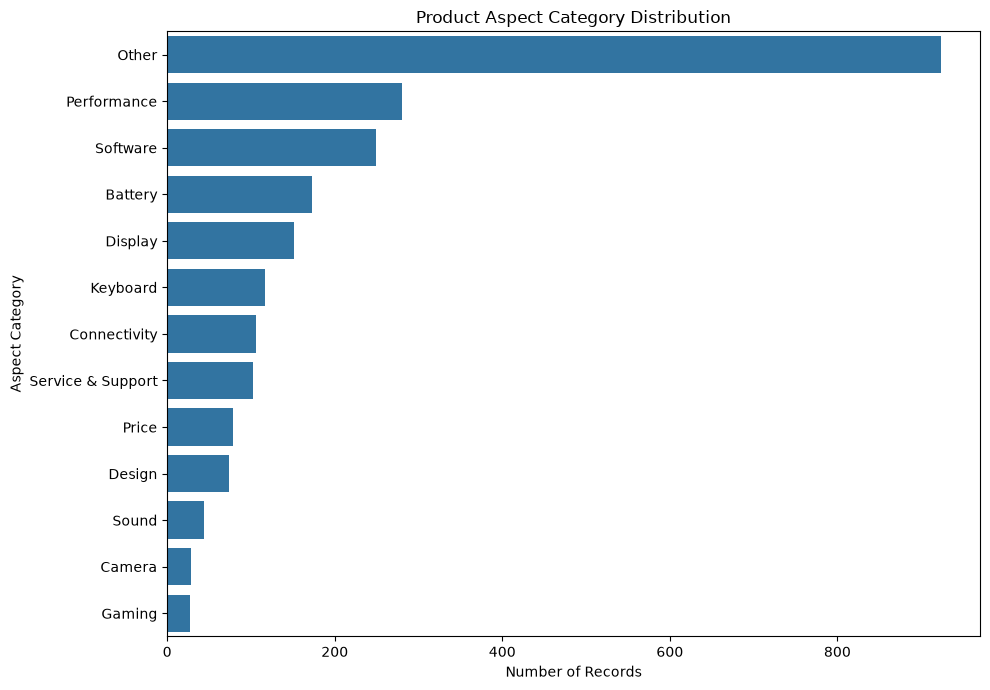

In [118]:
category_counts = (
    aspect_df["Aspect Category"]
    .value_counts()
)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title(
    "Product Aspect Category Distribution"
)

plt.xlabel(
    "Number of Records"
)

plt.ylabel(
    "Aspect Category"
)

plt.tight_layout()

plt.show()

In [119]:
category_percentage = (
    aspect_df["Aspect Category"]
    .value_counts(normalize=True)
    * 100
)

category_percentage = (
    category_percentage.round(2)
)

print(
    category_percentage
)

Aspect Category
Other                39.25
Performance          11.89
Software             10.58
Battery               7.35
Display               6.41
Keyboard              4.97
Connectivity          4.50
Service & Support     4.33
Price                 3.36
Design                3.14
Sound                 1.87
Camera                1.19
Gaming                1.15
Name: proportion, dtype: float64


In [120]:
aspect_sentiment = pd.crosstab(
    aspect_df["Aspect Category"],
    aspect_df["polarity"]
)

aspect_sentiment

polarity,conflict,negative,neutral,positive
Aspect Category,,,,
Battery,5,90,20,58
Camera,1,6,5,16
Connectivity,3,48,23,32
Design,1,17,4,52
Display,8,46,18,79
Gaming,0,5,16,6
Keyboard,2,45,19,51
Other,11,330,183,400
Performance,2,91,72,115


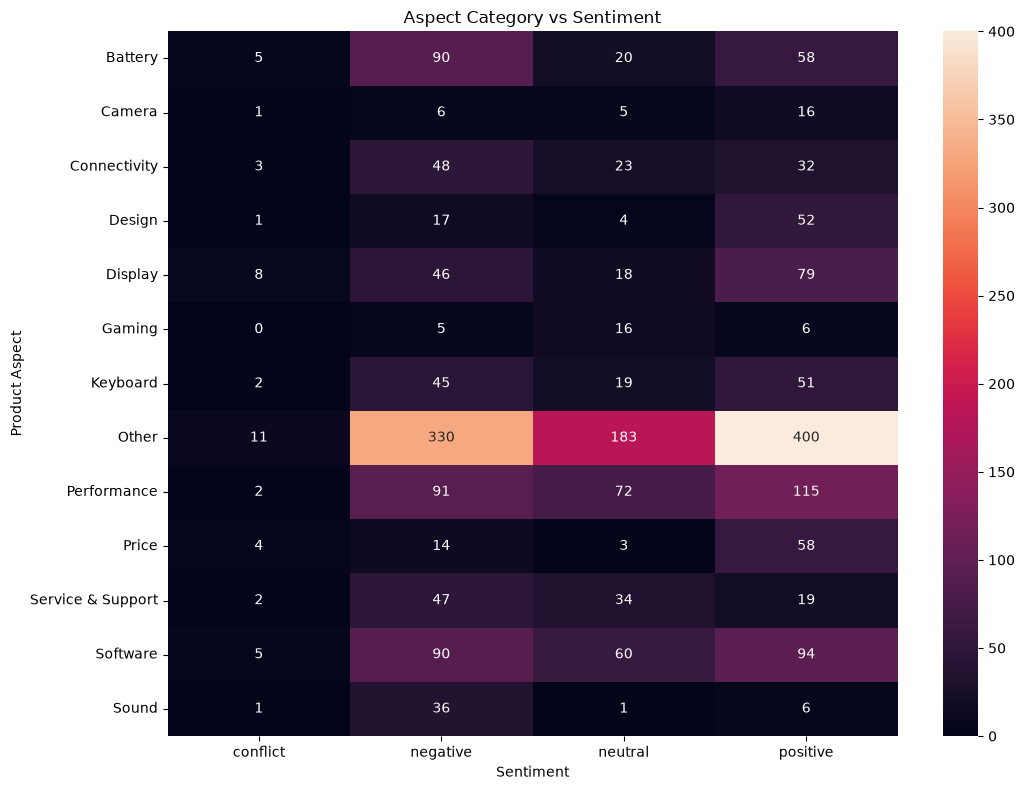

In [121]:
plt.figure(
    figsize=(11, 8)
)

sns.heatmap(
    aspect_sentiment,
    annot=True,
    fmt="d"
)

plt.title(
    "Aspect Category vs Sentiment"
)

plt.xlabel(
    "Sentiment"
)

plt.ylabel(
    "Product Aspect"
)

plt.tight_layout()

plt.show()

In [122]:
aspect_sentiment_percentage = pd.crosstab(
    aspect_df["Aspect Category"],
    aspect_df["polarity"],
    normalize="index"
) * 100

aspect_sentiment_percentage = (
    aspect_sentiment_percentage.round(2)
)

aspect_sentiment_percentage

polarity,conflict,negative,neutral,positive
Aspect Category,,,,
Battery,2.89,52.02,11.56,33.53
Camera,3.57,21.43,17.86,57.14
Connectivity,2.83,45.28,21.70,30.19
Design,1.35,22.97,5.41,70.27
Display,5.30,30.46,11.92,52.32
Gaming,0.00,18.52,59.26,22.22
Keyboard,1.71,38.46,16.24,43.59
Other,1.19,35.71,19.81,43.29
Performance,0.71,32.50,25.71,41.07


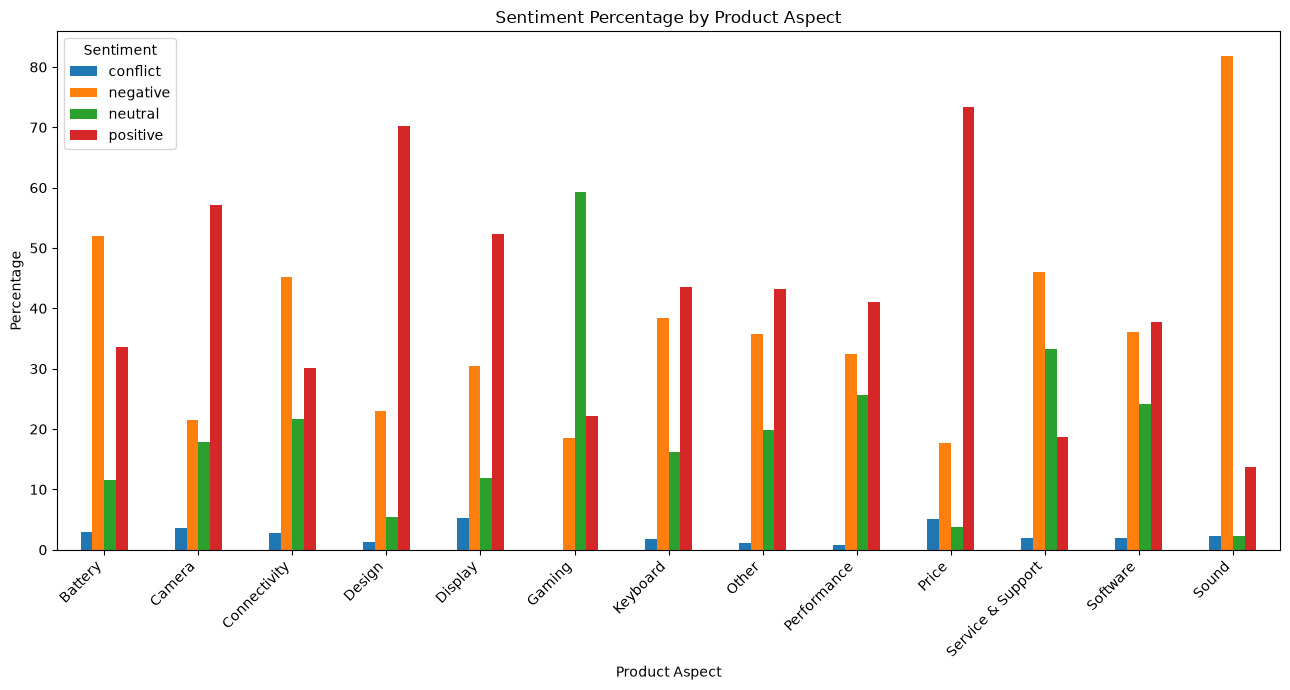

In [123]:
aspect_sentiment_percentage.plot(
    kind="bar",
    figsize=(13, 7)
)

plt.title(
    "Sentiment Percentage by Product Aspect"
)

plt.xlabel(
    "Product Aspect"
)

plt.ylabel(
    "Percentage"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    title="Sentiment"
)

plt.tight_layout()

plt.show()

In [124]:
if "positive" in aspect_sentiment_percentage.columns:

    most_positive = (
        aspect_sentiment_percentage[
            "positive"
        ]
        .sort_values(
            ascending=False
        )
    )

    print(
        "Most positively perceived aspects:"
    )

    print(
        most_positive
    )

Most positively perceived aspects:
Aspect Category
Price                73.42
Design               70.27
Camera               57.14
Display              52.32
Keyboard             43.59
Other                43.29
Performance          41.07
Software             37.75
Battery              33.53
Connectivity         30.19
Gaming               22.22
Service & Support    18.63
Sound                13.64
Name: positive, dtype: float64


In [125]:
if "negative" in aspect_sentiment_percentage.columns:

    most_negative = (
        aspect_sentiment_percentage[
            "negative"
        ]
        .sort_values(
            ascending=False
        )
    )

    print(
        "Most negatively perceived aspects:"
    )

    print(
        most_negative
    )

Most negatively perceived aspects:
Aspect Category
Sound                81.82
Battery              52.02
Service & Support    46.08
Connectivity         45.28
Keyboard             38.46
Software             36.14
Other                35.71
Performance          32.50
Display              30.46
Design               22.97
Camera               21.43
Gaming               18.52
Price                17.72
Name: negative, dtype: float64


In [126]:
aspect_summary = (
    aspect_df
    .groupby("Aspect Category")
    .agg(
        Total_Reviews=("Aspect Category", "size")
    )
)

aspect_summary

,Total_Reviews
Aspect Category,
Battery,173
Camera,28
Connectivity,106
Design,74
Display,151
Gaming,27
Keyboard,117
Other,924
Performance,280


In [127]:
aspect_summary = pd.crosstab(
    aspect_df["Aspect Category"],
    aspect_df["polarity"]
)

aspect_summary["Total"] = (
    aspect_summary.sum(axis=1)
)

aspect_summary = aspect_summary.sort_values(
    "Total",
    ascending=False
)

aspect_summary

polarity,conflict,negative,neutral,positive,Total
Aspect Category,,,,,
Other,11,330,183,400,924
Performance,2,91,72,115,280
Software,5,90,60,94,249
Battery,5,90,20,58,173
Display,8,46,18,79,151
Keyboard,2,45,19,51,117
Connectivity,3,48,23,32,106
Service & Support,2,47,34,19,102
Price,4,14,3,58,79


In [128]:
aspect_df.to_csv(
    "aspect_analysis_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Aspect analysis dataset saved successfully!"
)

Aspect analysis dataset saved successfully!


In [129]:
aspect_df.to_csv(
    "aspect_analysis_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Aspect analysis dataset saved successfully!"
)

Aspect analysis dataset saved successfully!


In [130]:
print(
    aspect_df.columns.tolist()
)

['id', 'Sentence', 'Aspect Term', 'polarity', 'from', 'to', 'Review Length', 'Word Count', 'Clean Sentence', 'Clean Aspect', 'Text Length', 'Processed Text', 'Processed Aspect', 'Model Text', 'Processed Word Count', 'Aspect Category']


In [131]:
# ============================================
# PHASE 6: EMOTION ANALYSIS
# ============================================

emotion_keywords = {

    "Joy": [
        "love",
        "loved",
        "lovely",
        "amazing",
        "awesome",
        "excellent",
        "fantastic",
        "wonderful",
        "perfect",
        "enjoy",
        "enjoyed",
        "happy",
        "great"
    ],

    "Satisfaction": [
        "good",
        "nice",
        "satisfied",
        "satisfaction",
        "pleased",
        "worth",
        "reliable",
        "useful",
        "recommend",
        "recommended",
        "like",
        "liked",
        "works well"
    ],

    "Frustration": [
        "slow",
        "lag",
        "laggy",
        "problem",
        "problems",
        "issue",
        "issues",
        "difficult",
        "difficulty",
        "annoying",
        "annoyed",
        "drain",
        "drains",
        "crash",
        "crashes",
        "freeze",
        "freezes",
        "overheat",
        "overheating",
        "hot"
    ],

    "Disappointment": [
        "disappointed",
        "disappointing",
        "disappoint",
        "expected",
        "expect",
        "worse",
        "poor",
        "below",
        "regret",
        "regretted",
        "unfortunately"
    ],

    "Anger": [
        "terrible",
        "horrible",
        "worst",
        "hate",
        "hated",
        "furious",
        "angry",
        "awful",
        "useless",
        "ridiculous",
        "unacceptable"
    ]
}

print("Emotion keyword dictionary created.")

for emotion, words in emotion_keywords.items():
    print(emotion, ":", len(words), "keywords")

Emotion keyword dictionary created.
Joy : 13 keywords
Satisfaction : 13 keywords
Frustration : 20 keywords
Disappointment : 11 keywords
Anger : 11 keywords


In [132]:
def detect_emotion(text, polarity):

    text = str(text).lower()

    emotion_scores = {
        emotion: 0
        for emotion in emotion_keywords
    }

    # Count emotion-related words
    for emotion, keywords in emotion_keywords.items():

        for keyword in keywords:

            if keyword in text:
                emotion_scores[emotion] += 1

    # Find emotion with highest score
    max_score = max(
        emotion_scores.values()
    )

    # No emotion word detected
    if max_score == 0:

        if polarity == "positive":
            return "Satisfaction"

        elif polarity == "negative":
            return "Frustration"

        else:
            return "Neutral"

    # Get emotion(s) having highest score
    best_emotions = [
        emotion
        for emotion, score in emotion_scores.items()
        if score == max_score
    ]

    # If one clear emotion
    if len(best_emotions) == 1:
        return best_emotions[0]

    # Tie-breaking using polarity
    if polarity == "positive":

        positive_emotions = [
            "Joy",
            "Satisfaction"
        ]

        for emotion in positive_emotions:
            if emotion in best_emotions:
                return emotion

    if polarity == "negative":

        negative_emotions = [
            "Anger",
            "Frustration",
            "Disappointment"
        ]

        for emotion in negative_emotions:
            if emotion in best_emotions:
                return emotion

    return best_emotions[0]

In [133]:
test_examples = [

    ("I love this laptop, it is amazing", "positive"),

    ("The battery drains quickly and it is annoying", "negative"),

    ("The product is terrible and useless", "negative"),

    ("I am disappointed with the display", "negative"),

    ("The laptop works well and is reliable", "positive"),

    ("The laptop has a keyboard", "neutral")
]

for text, polarity in test_examples:

    emotion = detect_emotion(
        text,
        polarity
    )

    print("Review:", text)
    print("Polarity:", polarity)
    print("Emotion:", emotion)
    print("-" * 60)

Review: I love this laptop, it is amazing
Polarity: positive
Emotion: Joy
------------------------------------------------------------
Review: The battery drains quickly and it is annoying
Polarity: negative
Emotion: Frustration
------------------------------------------------------------
Review: The product is terrible and useless
Polarity: negative
Emotion: Anger
------------------------------------------------------------
Review: I am disappointed with the display
Polarity: negative
Emotion: Disappointment
------------------------------------------------------------
Review: The laptop works well and is reliable
Polarity: positive
Emotion: Satisfaction
------------------------------------------------------------
Review: The laptop has a keyboard
Polarity: neutral
Emotion: Neutral
------------------------------------------------------------


In [134]:
aspect_df["Emotion"] = aspect_df.apply(
    lambda row: detect_emotion(
        row["Processed Text"],
        row["polarity"]
    ),
    axis=1
)

print("Emotion labels generated successfully!")

Emotion labels generated successfully!


In [135]:
emotion_counts = (
    aspect_df["Emotion"]
    .value_counts()
)

print("Emotion Distribution:")
print(emotion_counts)

Emotion Distribution:
Emotion
Frustration       804
Satisfaction      724
Joy               387
Neutral           345
Anger              51
Disappointment     43
Name: count, dtype: int64


In [136]:
emotion_percentage = (
    aspect_df["Emotion"]
    .value_counts(normalize=True)
    * 100
).round(2)

print("\nEmotion Percentage:")
print(emotion_percentage)


Emotion Percentage:
Emotion
Frustration       34.15
Satisfaction      30.76
Joy               16.44
Neutral           14.66
Anger              2.17
Disappointment     1.83
Name: proportion, dtype: float64


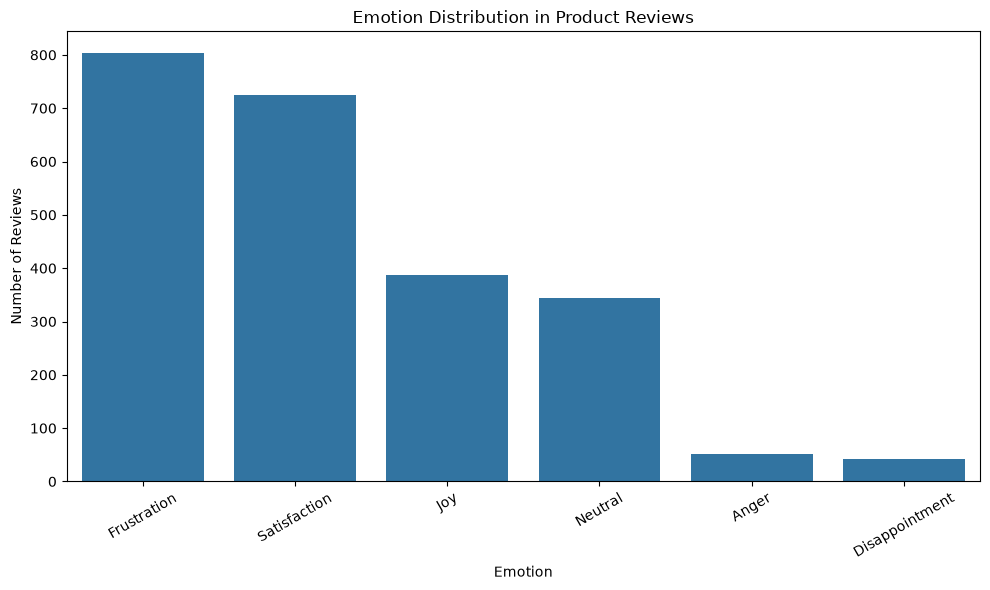

In [137]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=aspect_df,
    x="Emotion",
    order=emotion_counts.index
)

plt.title(
    "Emotion Distribution in Product Reviews"
)

plt.xlabel("Emotion")
plt.ylabel("Number of Reviews")

plt.xticks(
    rotation=30
)

plt.tight_layout()

plt.show()

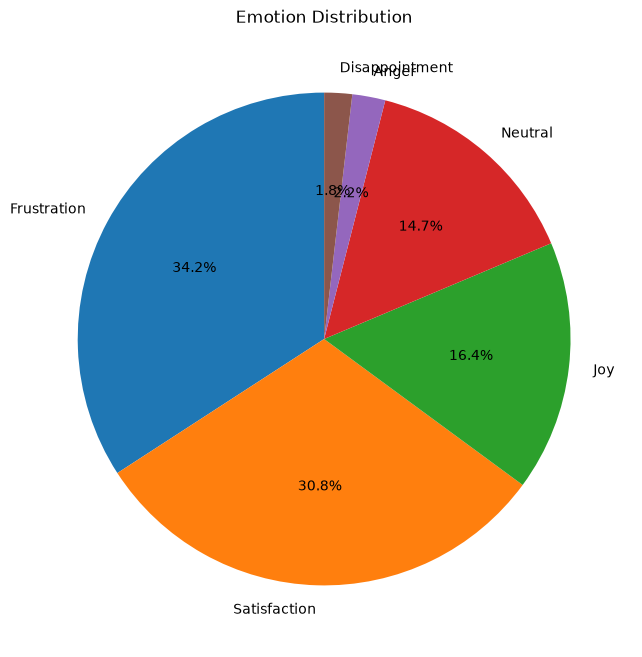

In [138]:
plt.figure(figsize=(8, 8))

plt.pie(
    emotion_counts.values,
    labels=emotion_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "Emotion Distribution"
)

plt.show()

In [139]:
polarity_emotion = pd.crosstab(
    aspect_df["polarity"],
    aspect_df["Emotion"]
)

polarity_emotion

Emotion,Anger,Disappointment,Frustration,Joy,Neutral,Satisfaction
polarity,,,,,,
conflict,2,1,4,6,25,7
negative,46,32,693,35,0,59
neutral,1,2,50,32,320,53
positive,2,8,57,314,0,605


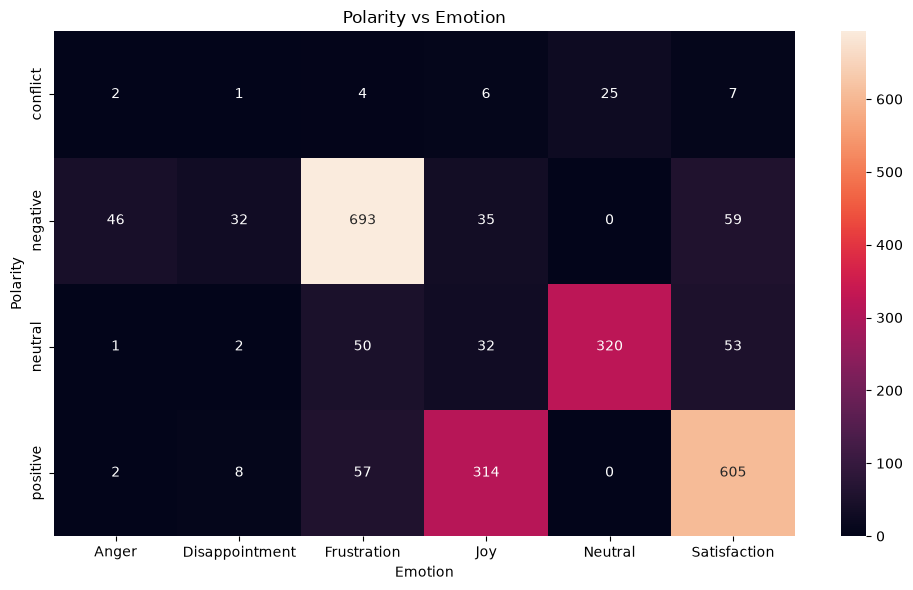

In [140]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    polarity_emotion,
    annot=True,
    fmt="d"
)

plt.title(
    "Polarity vs Emotion"
)

plt.xlabel("Emotion")
plt.ylabel("Polarity")

plt.tight_layout()

plt.show()

In [141]:
aspect_emotion = pd.crosstab(
    aspect_df["Aspect Category"],
    aspect_df["Emotion"]
)

aspect_emotion

Emotion,Anger,Disappointment,Frustration,Joy,Neutral,Satisfaction
Aspect Category,,,,,,
Battery,1,3,83,32,19,35
Camera,0,0,10,8,4,6
Connectivity,6,3,43,8,18,28
Design,1,0,17,20,4,32
Display,7,1,36,36,18,53
Gaming,0,0,6,8,7,6
Keyboard,5,1,41,19,10,41
Other,20,19,307,158,140,280
Performance,1,6,93,32,54,94


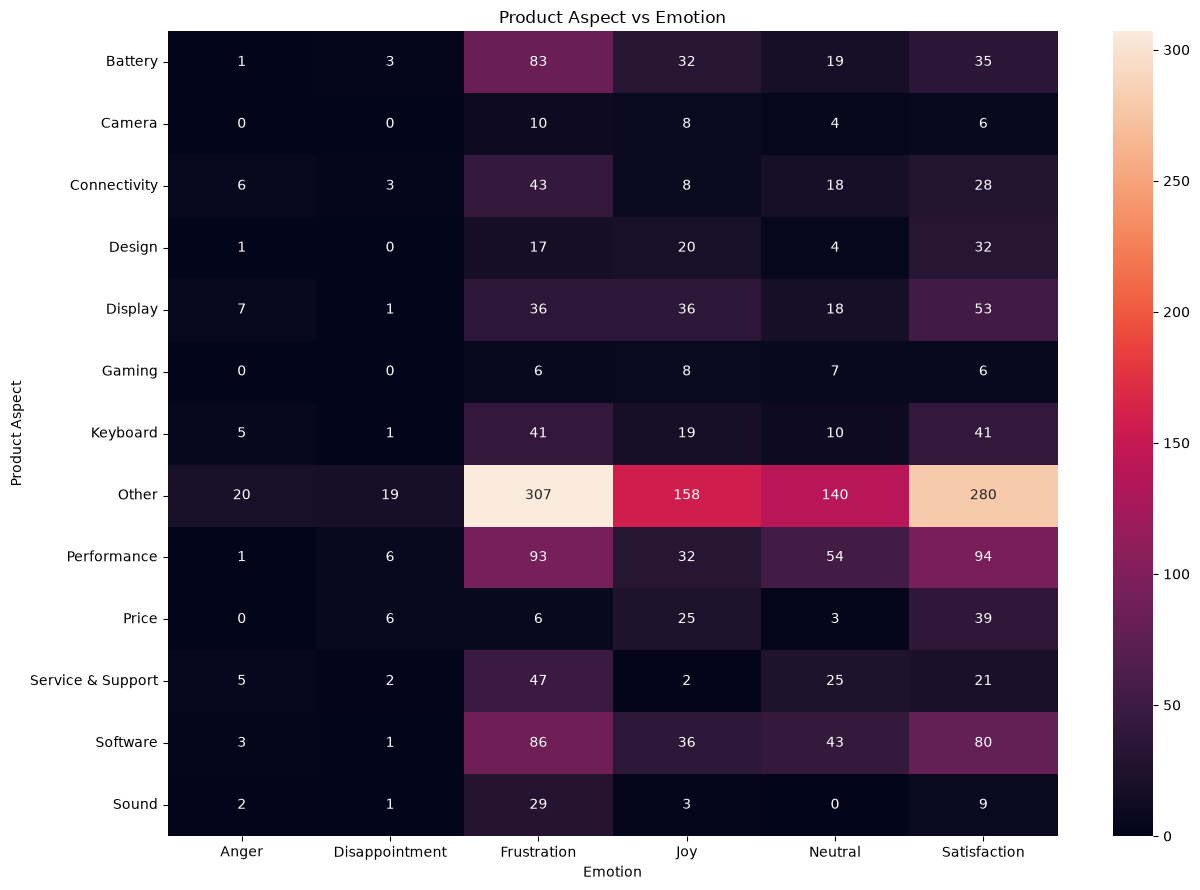

In [142]:
plt.figure(figsize=(13, 9))

sns.heatmap(
    aspect_emotion,
    annot=True,
    fmt="d"
)

plt.title(
    "Product Aspect vs Emotion"
)

plt.xlabel("Emotion")
plt.ylabel("Product Aspect")

plt.tight_layout()

plt.show()

In [143]:
aspect_emotion_percentage = pd.crosstab(
    aspect_df["Aspect Category"],
    aspect_df["Emotion"],
    normalize="index"
) * 100

aspect_emotion_percentage = (
    aspect_emotion_percentage.round(2)
)

aspect_emotion_percentage

Emotion,Anger,Disappointment,Frustration,Joy,Neutral,Satisfaction
Aspect Category,,,,,,
Battery,0.58,1.73,47.98,18.50,10.98,20.23
Camera,0.00,0.00,35.71,28.57,14.29,21.43
Connectivity,5.66,2.83,40.57,7.55,16.98,26.42
Design,1.35,0.00,22.97,27.03,5.41,43.24
Display,4.64,0.66,23.84,23.84,11.92,35.10
Gaming,0.00,0.00,22.22,29.63,25.93,22.22
Keyboard,4.27,0.85,35.04,16.24,8.55,35.04
Other,2.16,2.06,33.23,17.10,15.15,30.30
Performance,0.36,2.14,33.21,11.43,19.29,33.57


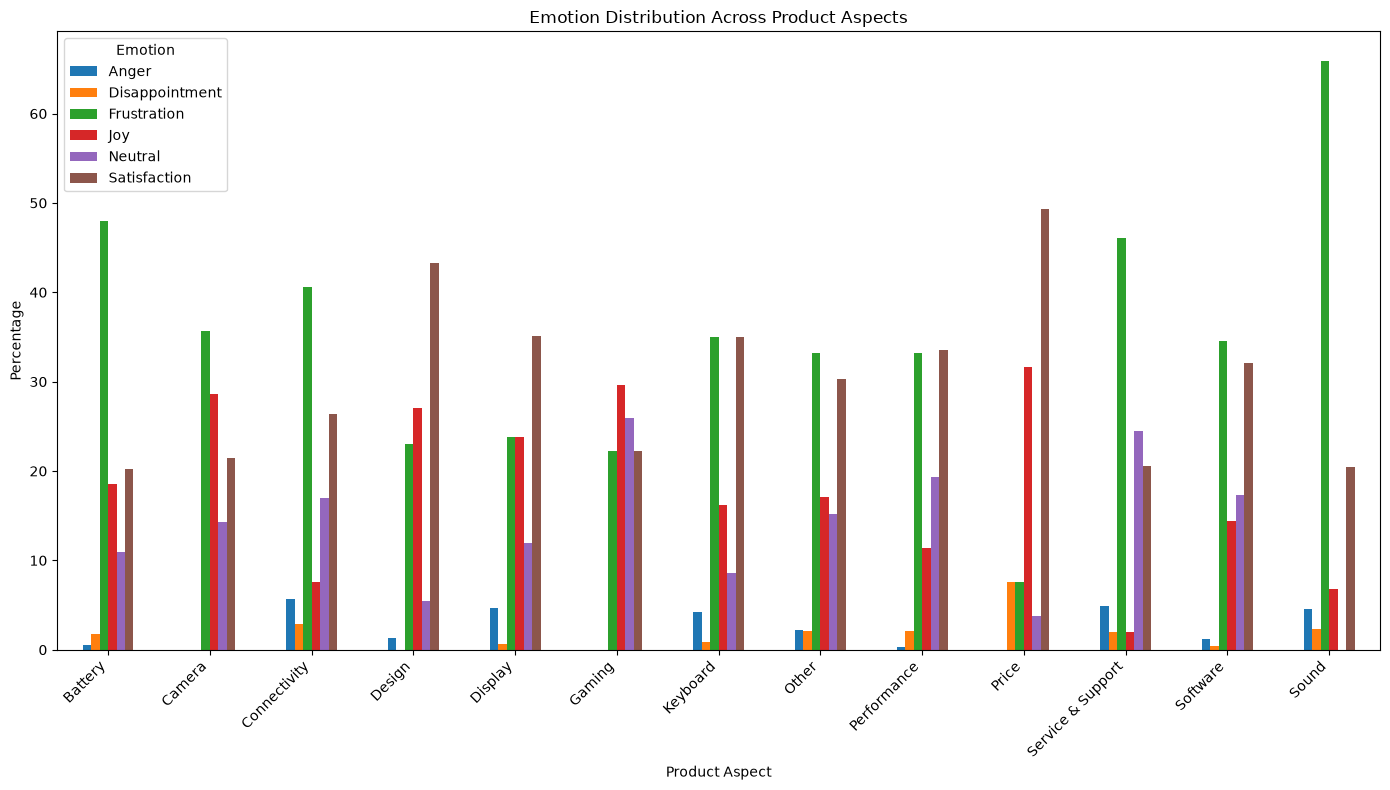

In [144]:
aspect_emotion_percentage.plot(
    kind="bar",
    figsize=(14, 8)
)

plt.title(
    "Emotion Distribution Across Product Aspects"
)

plt.xlabel(
    "Product Aspect"
)

plt.ylabel(
    "Percentage"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    title="Emotion"
)

plt.tight_layout()

plt.show()

In [145]:
dominant_emotion = (
    aspect_emotion
    .idxmax(axis=1)
)

dominant_count = (
    aspect_emotion
    .max(axis=1)
)

dominant_aspect_emotion = pd.DataFrame({

    "Dominant Emotion": dominant_emotion,

    "Number of Reviews": dominant_count

})

dominant_aspect_emotion

,Dominant Emotion,Number of Reviews
Aspect Category,,
Battery,Frustration,83
Camera,Frustration,10
Connectivity,Frustration,43
Design,Satisfaction,32
Display,Satisfaction,53
Gaming,Joy,8
Keyboard,Frustration,41
Other,Frustration,307
Performance,Satisfaction,94


In [146]:
emotion_score = {

    "Neutral": 0,

    "Satisfaction": 1,

    "Joy": 2,

    "Disappointment": -1,

    "Frustration": -2,

    "Anger": -3
}

In [147]:
aspect_df["Emotion Score"] = (
    aspect_df["Emotion"]
    .map(emotion_score)
)

aspect_df[
    [
        "Aspect Category",
        "polarity",
        "Emotion",
        "Emotion Score"
    ]
].head(20)

,Aspect Category,polarity,Emotion,Emotion Score
0,Other,neutral,Satisfaction,1
1,Battery,positive,Satisfaction,1
2,Service & Support,negative,Frustration,-2
3,Other,negative,Frustration,-2
4,Other,neutral,Neutral,0
5,Other,positive,Satisfaction,1
6,Other,positive,Satisfaction,1
7,Software,positive,Satisfaction,1
8,Other,positive,Satisfaction,1
9,Other,positive,Frustration,-2


In [148]:
emotion_spectrum = (
    aspect_df
    .groupby("Aspect Category")[
        "Emotion Score"
    ]
    .mean()
    .sort_values()
)

print(
    "Average Emotion Score by Aspect:"
)

print(
    emotion_spectrum.round(2)
)

Average Emotion Score by Aspect:
Aspect Category
Sound               -1.14
Service & Support   -0.84
Connectivity        -0.59
Battery             -0.42
Keyboard            -0.16
Performance         -0.13
Software            -0.12
Other               -0.10
Camera               0.07
Display              0.21
Gaming               0.37
Design               0.47
Price                0.90
Name: Emotion Score, dtype: float64


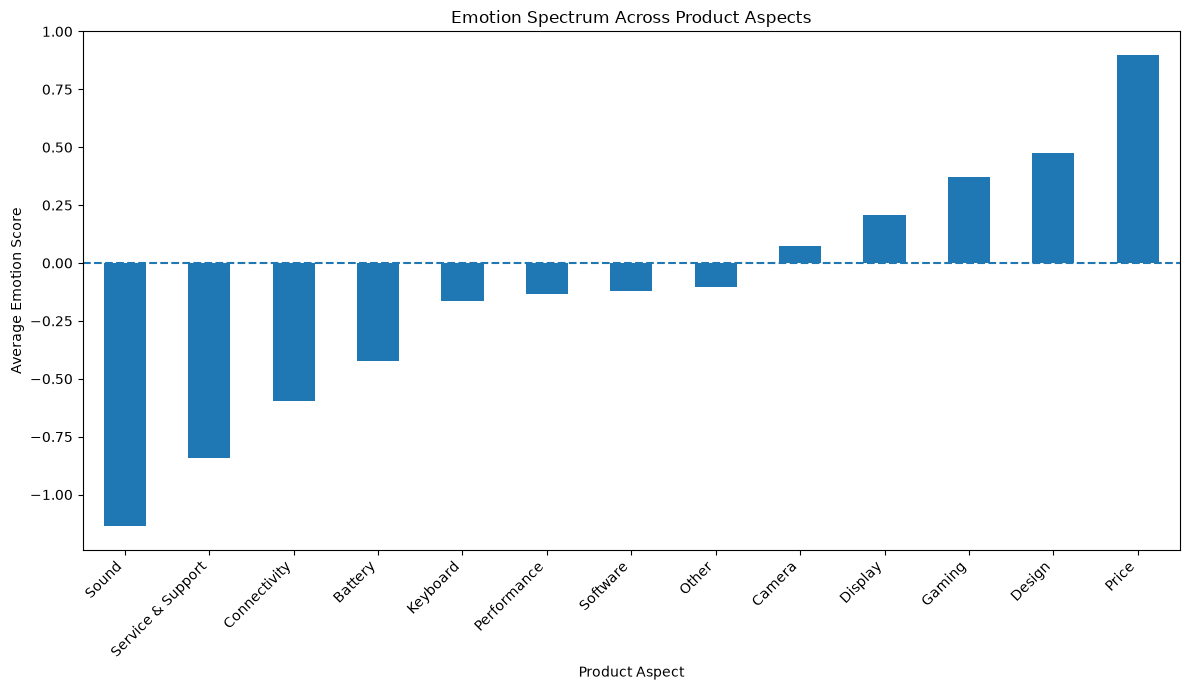

In [149]:
plt.figure(figsize=(12, 7))

emotion_spectrum.plot(
    kind="bar"
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(
    "Emotion Spectrum Across Product Aspects"
)

plt.xlabel(
    "Product Aspect"
)

plt.ylabel(
    "Average Emotion Score"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

In [150]:
aspect_df[
    [
        "Sentence",
        "Aspect Term",
        "Aspect Category",
        "polarity",
        "Emotion",
        "Emotion Score"
    ]
].sample(
    20,
    random_state=42
)

,Sentence,Aspect Term,Aspect Category,polarity,Emotion,Emotion Score
1904,I regret buying it before understanding how aw...,use,Other,negative,Anger,-3
670,and the multiple page viewer ( allows you to p...,multiple page viewer,Other,positive,Joy,2
694,"We have had numerous problems with Vista, su...",Vista,Other,negative,Anger,-3
1889,You can even run a parallels type program easi...,software,Software,positive,Satisfaction,1
1178,Features such as the Dashboard (allows you to ...,Features,Other,neutral,Satisfaction,1
1975,They should have included more memory on their...,Vista,Other,negative,Frustration,-2
383,"The computer itself was fast, ran smoothly, an...",ran,Other,positive,Frustration,-2
111,It has a 10 hour battery life when you're doin...,battery life,Battery,positive,Joy,2
1181,I sent it back and found this time that the ...,battery,Battery,negative,Frustration,-2
1971,Speakers too small to be of any real use.,Speakers,Sound,negative,Frustration,-2


In [151]:
aspect_df.to_csv(
    "emotion_analysis_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Emotion analysis dataset saved successfully!"
)

Emotion analysis dataset saved successfully!


In [152]:
aspect_df.to_csv(
    "emotion_analysis_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Emotion analysis dataset saved successfully!"
)

Emotion analysis dataset saved successfully!


In [153]:
# ============================================
# PHASE 7: EMOTION VALIDATION
# ============================================

ml_df = pd.read_csv(
    "emotion_analysis_dataset.csv"
)

print("Dataset shape:", ml_df.shape)

ml_df.head()

Dataset shape: (2354, 18)


,id,Sentence,Aspect Term,polarity,from,to,Review Length,Word Count,Clean Sentence,Clean Aspect,Text Length,Processed Text,Processed Aspect,Model Text,Processed Word Count,Aspect Category,Emotion,Emotion Score
0,2339,I charge it at night and skip taking the cord ...,cord,neutral,41,45,87,18,i charge it at night and skip taking the cord ...,cord,86,charge night skip taking cord good battery life,cord,charge night skip taking cord good battery lif...,8,Other,Satisfaction,1
1,2339,I charge it at night and skip taking the cord ...,battery life,positive,74,86,87,18,i charge it at night and skip taking the cord ...,battery life,86,charge night skip taking cord good battery life,battery life,charge night skip taking cord good battery lif...,8,Battery,Satisfaction,1
2,1316,The tech guy then said the service center does...,service center,negative,27,41,179,35,the tech guy then said the service center does...,service center,171,tech guy said service center not exchange dire...,service center,tech guy said service center not exchange dire...,15,Service & Support,Frustration,-2
3,1316,The tech guy then said the service center does...,"""sales"" team",negative,109,121,179,35,the tech guy then said the service center does...,sales team,171,tech guy said service center not exchange dire...,sale team,tech guy said service center not exchange dire...,15,Other,Frustration,-2
4,1316,The tech guy then said the service center does...,tech guy,neutral,4,12,179,35,the tech guy then said the service center does...,tech guy,171,tech guy said service center not exchange dire...,tech guy,tech guy said service center not exchange dire...,15,Other,Neutral,0


In [154]:
print("\nNumber of emotion classes:")

print(
    ml_df["Emotion"].nunique()
)


Number of emotion classes:
6


In [157]:
print("Emotion classes:")

print(
    ml_df["Emotion"].unique()
)

Emotion classes:
<StringArray>
['Satisfaction', 'Frustration', 'Neutral', 'Joy', 'Disappointment', 'Anger']
Length: 6, dtype: str


In [158]:
print("\nNumber of emotion classes:")

print(
    ml_df["Emotion"].nunique()
)


Number of emotion classes:
6


In [159]:
emotion_counts = (
    ml_df["Emotion"]
    .value_counts()
)

print(
    emotion_counts
)

Emotion
Frustration       804
Satisfaction      724
Joy               387
Neutral           345
Anger              51
Disappointment     43
Name: count, dtype: int64


In [160]:
emotion_percentage = (
    ml_df["Emotion"]
    .value_counts(normalize=True)
    * 100
).round(2)

print(
    emotion_percentage
)

Emotion
Frustration       34.15
Satisfaction      30.76
Joy               16.44
Neutral           14.66
Anger              2.17
Disappointment     1.83
Name: proportion, dtype: float64


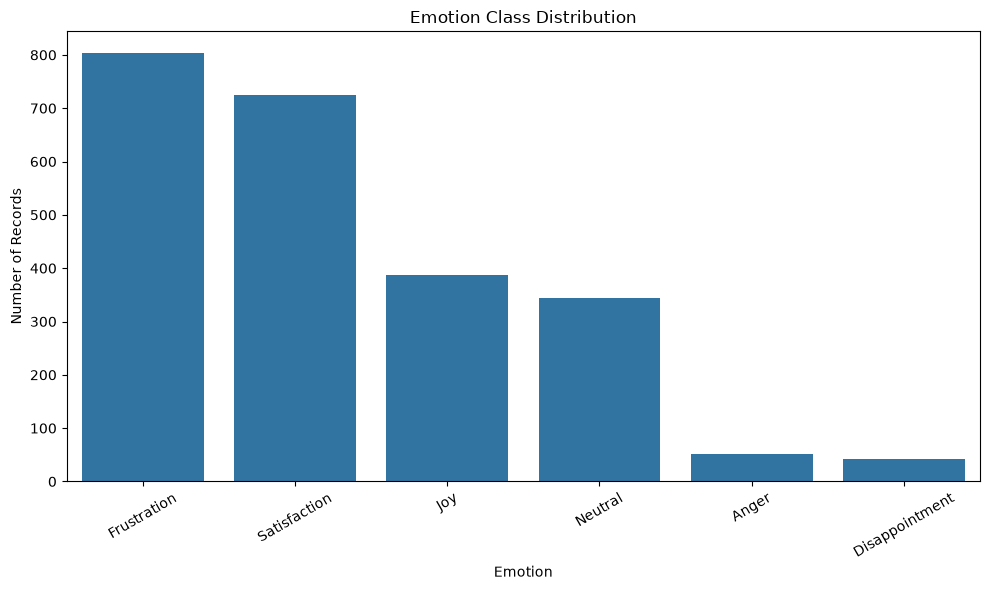

In [161]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=ml_df,
    x="Emotion",
    order=emotion_counts.index
)

plt.title(
    "Emotion Class Distribution"
)

plt.xlabel("Emotion")
plt.ylabel("Number of Records")

plt.xticks(
    rotation=30
)

plt.tight_layout()

plt.show()

In [162]:
for emotion in ml_df["Emotion"].unique():

    print("\n")
    print("=" * 70)
    print("EMOTION:", emotion)
    print("=" * 70)

    examples = ml_df[
        ml_df["Emotion"] == emotion
    ][
        [
            "Sentence",
            "Aspect Category",
            "polarity"
        ]
    ].sample(
        min(
            5,
            len(
                ml_df[
                    ml_df["Emotion"] == emotion
                ]
            )
        ),
        random_state=42
    )

    print(examples.to_string(index=False))



EMOTION: Satisfaction
                                                                                                                                                                                                                                                                        Sentence Aspect Category polarity
                                                                                                                It's graphics aren't bad at all, for the lower end of the MacBook Pro spectrum, easily capable of running StarCraft II and other games with comparable graphics.         Display positive
                                                                                                                                                   This laptop looks great on the surface: 17" inch screen, good  price-point, nice appearance, boots up quickly, runs fast etc.         Display positive
                                                                                  

In [163]:
emotion_polarity_table = pd.crosstab(
    ml_df["Emotion"],
    ml_df["polarity"]
)

emotion_polarity_table

polarity,conflict,negative,neutral,positive
Emotion,,,,
Anger,2,46,1,2
Disappointment,1,32,2,8
Frustration,4,693,50,57
Joy,6,35,32,314
Neutral,25,0,320,0
Satisfaction,7,59,53,605


In [164]:
emotion_aspect_table = pd.crosstab(
    ml_df["Aspect Category"],
    ml_df["Emotion"]
)

emotion_aspect_table

Emotion,Anger,Disappointment,Frustration,Joy,Neutral,Satisfaction
Aspect Category,,,,,,
Battery,1,3,83,32,19,35
Camera,0,0,10,8,4,6
Connectivity,6,3,43,8,18,28
Design,1,0,17,20,4,32
Display,7,1,36,36,18,53
Gaming,0,0,6,8,7,6
Keyboard,5,1,41,19,10,41
Other,20,19,307,158,140,280
Performance,1,6,93,32,54,94


In [165]:
duplicate_inputs = (
    ml_df["Model Text"]
    .duplicated()
    .sum()
)

print(
    "Duplicate model inputs:",
    duplicate_inputs
)

Duplicate model inputs: 76


In [166]:
ml_df = ml_df.drop_duplicates(
    subset=[
        "Model Text",
        "Emotion"
    ]
).reset_index(drop=True)

print(
    "Dataset shape after duplicate removal:",
    ml_df.shape
)

Dataset shape after duplicate removal: (2288, 18)


In [167]:
print(
    ml_df[
        [
            "Sentence",
            "Aspect Term",
            "Aspect Category",
            "polarity",
            "Emotion",
            "Emotion Score",
            "Model Text"
        ]
    ].head(10)
)

                                            Sentence     Aspect Term  \
0  I charge it at night and skip taking the cord ...            cord   
1  I charge it at night and skip taking the cord ...    battery life   
2  The tech guy then said the service center does...  service center   
3  The tech guy then said the service center does...    "sales" team   
4  The tech guy then said the service center does...        tech guy   
5  it is of high quality, has a killer GUI, is ex...         quality   
6  it is of high quality, has a killer GUI, is ex...             GUI   
7  it is of high quality, has a killer GUI, is ex...    applications   
8  it is of high quality, has a killer GUI, is ex...             use   
9  Easy to start up and does not overheat as much...        start up   

     Aspect Category  polarity       Emotion  Emotion Score  \
0              Other   neutral  Satisfaction              1   
1            Battery  positive  Satisfaction              1   
2  Service & Suppo

In [168]:

print(
    ml_df[
        [
            "Sentence",
            "Aspect Term",
            "Aspect Category",
            "polarity",
            "Emotion",
            "Emotion Score",
            "Model Text"
        ]
    ].head(10)
)

                                            Sentence     Aspect Term  \
0  I charge it at night and skip taking the cord ...            cord   
1  I charge it at night and skip taking the cord ...    battery life   
2  The tech guy then said the service center does...  service center   
3  The tech guy then said the service center does...    "sales" team   
4  The tech guy then said the service center does...        tech guy   
5  it is of high quality, has a killer GUI, is ex...         quality   
6  it is of high quality, has a killer GUI, is ex...             GUI   
7  it is of high quality, has a killer GUI, is ex...    applications   
8  it is of high quality, has a killer GUI, is ex...             use   
9  Easy to start up and does not overheat as much...        start up   

     Aspect Category  polarity       Emotion  Emotion Score  \
0              Other   neutral  Satisfaction              1   
1            Battery  positive  Satisfaction              1   
2  Service & Suppo

In [169]:
print(
    ml_df[
        [
            "Sentence",
            "Aspect Term",
            "Aspect Category",
            "polarity",
            "Emotion",
            "Emotion Score",
            "Model Text"
        ]
    ].head(10)
)

                                            Sentence     Aspect Term  \
0  I charge it at night and skip taking the cord ...            cord   
1  I charge it at night and skip taking the cord ...    battery life   
2  The tech guy then said the service center does...  service center   
3  The tech guy then said the service center does...    "sales" team   
4  The tech guy then said the service center does...        tech guy   
5  it is of high quality, has a killer GUI, is ex...         quality   
6  it is of high quality, has a killer GUI, is ex...             GUI   
7  it is of high quality, has a killer GUI, is ex...    applications   
8  it is of high quality, has a killer GUI, is ex...             use   
9  Easy to start up and does not overheat as much...        start up   

     Aspect Category  polarity       Emotion  Emotion Score  \
0              Other   neutral  Satisfaction              1   
1            Battery  positive  Satisfaction              1   
2  Service & Suppo

In [170]:
X = ml_df["Model Text"]

y = ml_df["Emotion"]

print("Input X shape:", X.shape)
print("Target y shape:", y.shape)

Input X shape: (2288,)
Target y shape: (2288,)


In [171]:
print(
    y.value_counts()
)

Emotion
Frustration       773
Satisfaction      713
Joy               372
Neutral           336
Anger              51
Disappointment     43
Name: count, dtype: int64


In [178]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

print(
    "Training samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

Training samples: 1830
Testing samples: 458


In [177]:
%pip install -U scikit-learn

  Using cached scikit_learn-1.9.0-cp314-cp314-win_amd64.whl.metadata (11 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached narwhals-2.25.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
Using cached scikit_learn-1.9.0-cp314-cp314-win_amd64.whl (8.3 MB)
Using cached narwhals-2.25.0-py3-none-any.whl (467 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)

   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- -------------

In [179]:
print("Training distribution:")
print(
    y_train.value_counts()
)

print("\nTesting distribution:")
print(
    y_test.value_counts()
)

Training distribution:
Emotion
Frustration       618
Satisfaction      570
Joy               298
Neutral           269
Anger              41
Disappointment     34
Name: count, dtype: int64

Testing distribution:
Emotion
Frustration       155
Satisfaction      143
Joy                74
Neutral            67
Anger              10
Disappointment      9
Name: count, dtype: int64


In [180]:
from sklearn.feature_extraction.text import TfidfVectorizer

print(
    "TF-IDF imported successfully!"
)

TF-IDF imported successfully!


In [181]:
tfidf = TfidfVectorizer(

    max_features=5000,

    ngram_range=(1, 2),

    min_df=2,

    max_df=0.95,

    sublinear_tf=True
)

print(
    "TF-IDF vectorizer created!"
)

TF-IDF vectorizer created!


In [182]:
X_train_tfidf = tfidf.fit_transform(
    X_train
)

X_test_tfidf = tfidf.transform(
    X_test
)

print(
    "Training TF-IDF shape:",
    X_train_tfidf.shape
)

print(
    "Testing TF-IDF shape:",
    X_test_tfidf.shape
)

Training TF-IDF shape: (1830, 5000)
Testing TF-IDF shape: (458, 5000)


In [183]:
feature_names = (
    tfidf.get_feature_names_out()
)

print(
    "Number of TF-IDF features:",
    len(feature_names)
)

print(
    "\nFirst 50 features:"
)

print(
    feature_names[:50]
)

Number of TF-IDF features: 5000

First 50 features:
['able' 'able buy' 'able connect' 'able find' 'able install' 'able load'
 'able run' 'able use' 'absolutely' 'absolutely amazing'
 'absolutely expensive' 'absolutely gorgeous' 'absolutely horrible'
 'absolutely not' 'abuse' 'ac' 'access' 'acer' 'acer get' 'acknowledge'
 'activity' 'actual' 'actual aspect' 'actually' 'actually hard' 'adapter'
 'add' 'add another' 'added' 'adding' 'adding program'
 'adding thunderbolt' 'additional' 'address' 'address book' 'adobe'
 'adobe creative' 'adobe flash' 'advanced' 'advanced learn' 'advantage'
 'advertised' 'affect' 'affect performance' 'affordability' 'aftereffect'
 'aftereffect program' 'agent' 'agent seemed' 'ago']


In [184]:
print(
    "TF-IDF matrix type:",
    type(X_train_tfidf)
)

print(
    "Number of non-zero values:",
    X_train_tfidf.nnz
)

TF-IDF matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Number of non-zero values: 28452


In [185]:
import joblib

os.makedirs(
    "models",
    exist_ok=True
)

joblib.dump(
    tfidf,
    "models/tfidf_vectorizer.pkl"
)

print(
    "TF-IDF vectorizer saved successfully!"
)

TF-IDF vectorizer saved successfully!


In [186]:
ml_df["Emotion"].value_counts()

Emotion
Frustration       773
Satisfaction      713
Joy               372
Neutral           336
Anger              51
Disappointment     43
Name: count, dtype: int64

In [187]:
pd.crosstab(
    ml_df["Emotion"],
    ml_df["polarity"]
)

polarity,conflict,negative,neutral,positive
Emotion,,,,
Anger,2,46,1,2
Disappointment,1,32,2,8
Frustration,4,663,50,56
Joy,6,31,32,303
Neutral,25,0,311,0
Satisfaction,7,58,52,596


In [188]:
ml_df[
    [
        "Sentence",
        "Aspect Category",
        "polarity",
        "Emotion"
    ]
].sample(20, random_state=42)

,Sentence,Aspect Category,polarity,Emotion
1249,They have developed excellent proprietary soft...,Software,positive,Joy
990,"Ever since I bought this laptop, so far I've e...",Software,negative,Frustration
809,"Small enough to use on a long flight, Light en...",Other,positive,Satisfaction
1043,This computer is exceptionally thin for it's s...,Battery,positive,Satisfaction
736,"Despite the inconvenient weight, I opted for t...",Battery,positive,Satisfaction
416,"however, I may have inadvertently thrown out o...",Other,neutral,Neutral
1633,"Other installed features, such as certain prin...",Other,positive,Satisfaction
196,"The Bluetooth was not there at all, and the fi...",Software,negative,Frustration
1376,After replacing the hard drive the battery sto...,Battery,negative,Frustration
2126,The acer one computer that I bought is 17 ince...,Display,positive,Satisfaction


In [189]:
# ============================================
# PHASE 8: MODEL TRAINING & EVALUATION
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [190]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\ny_train:")
print(y_train.value_counts())

print("\ny_test:")
print(y_test.value_counts())

X_train: (1830,)
X_test : (458,)

y_train:
Emotion
Frustration       618
Satisfaction      570
Joy               298
Neutral           269
Anger              41
Disappointment     34
Name: count, dtype: int64

y_test:
Emotion
Frustration       155
Satisfaction      143
Joy                74
Neutral            67
Anger              10
Disappointment      9
Name: count, dtype: int64


In [191]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

print("Models created:")
for name in models:
    print("→", name)

Models created:
→ Logistic Regression
→ Multinomial Naive Bayes
→ Linear SVM


In [192]:
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(
        X_train_tfidf,
        y_train
    )

    trained_models[name] = model

    print(
        name,
        "trained successfully!"
    )


Training: Logistic Regression
Logistic Regression trained successfully!

Training: Multinomial Naive Bayes
Multinomial Naive Bayes trained successfully!

Training: Linear SVM
Linear SVM trained successfully!


In [193]:
predictions = {}

for name, model in trained_models.items():

    predictions[name] = model.predict(
        X_test_tfidf
    )

print("Predictions generated successfully!")

Predictions generated successfully!


In [194]:
results = []

for name in trained_models:

    y_pred = predictions[name]

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({

        "Model": name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.766376,0.776992,0.766376,0.770366
1,Multinomial Naive Bayes,0.689956,0.711858,0.689956,0.638795
2,Linear SVM,0.812227,0.813035,0.812227,0.812235


In [195]:
results_percentage = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_percentage[metric_columns] = (
    results_percentage[metric_columns] * 100
).round(2)

results_percentage

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,76.64,77.70,76.64,77.04
1,Multinomial Naive Bayes,69.00,71.19,69.00,63.88
2,Linear SVM,81.22,81.30,81.22,81.22


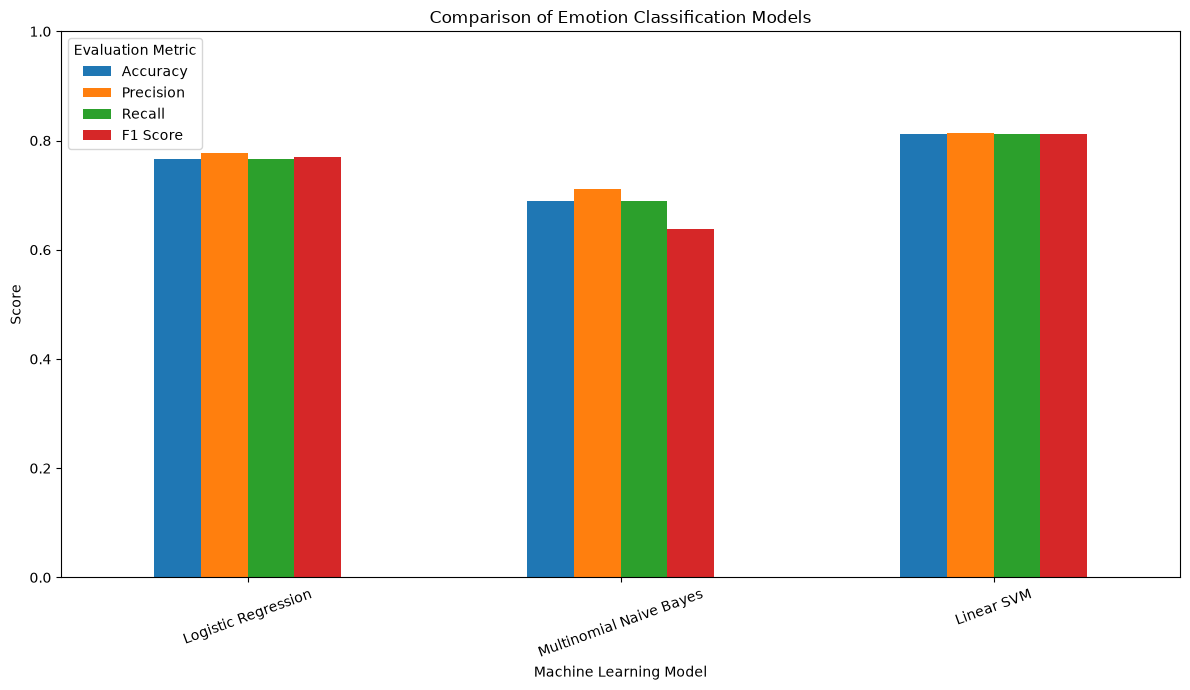

In [196]:
results_plot = results_df.set_index(
    "Model"
)

results_plot[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
].plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title(
    "Comparison of Emotion Classification Models"
)

plt.xlabel("Machine Learning Model")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(
    rotation=20
)

plt.legend(
    title="Evaluation Metric"
)

plt.tight_layout()

plt.show()

In [197]:
best_model_name = (
    results_df
    .sort_values(
        "F1 Score",
        ascending=False
    )
    .iloc[0]["Model"]
)

best_model = trained_models[
    best_model_name
]

best_prediction = predictions[
    best_model_name
]

print(
    "Best Emotion Model:",
    best_model_name
)

print(
    "Best F1 Score:",
    round(
        results_df[
            results_df["Model"] == best_model_name
        ]["F1 Score"].iloc[0],
        4
    )
)

Best Emotion Model: Linear SVM
Best F1 Score: 0.8122


In [198]:
print(
    "Classification Report -",
    best_model_name
)

print()

print(
    classification_report(
        y_test,
        best_prediction,
        zero_division=0
    )
)

Classification Report - Linear SVM

                precision    recall  f1-score   support

         Anger       1.00      0.90      0.95        10
Disappointment       1.00      0.78      0.88         9
   Frustration       0.82      0.83      0.82       155
           Joy       0.93      0.96      0.95        74
       Neutral       0.55      0.55      0.55        67
  Satisfaction       0.84      0.83      0.84       143

      accuracy                           0.81       458
     macro avg       0.86      0.81      0.83       458
  weighted avg       0.81      0.81      0.81       458



In [202]:
cm = confusion_matrix(
    y_test,
    best_prediction,
    labels=best_model.classes_
)

print(cm)

[[  9   0   1   0   0   0]
 [  0   7   1   1   0   0]
 [  0   0 129   1  16   9]
 [  0   0   2  71   0   1]
 [  0   0  16   2  37  12]
 [  0   0   9   1  14 119]]


<Figure size 900x800 with 0 Axes>

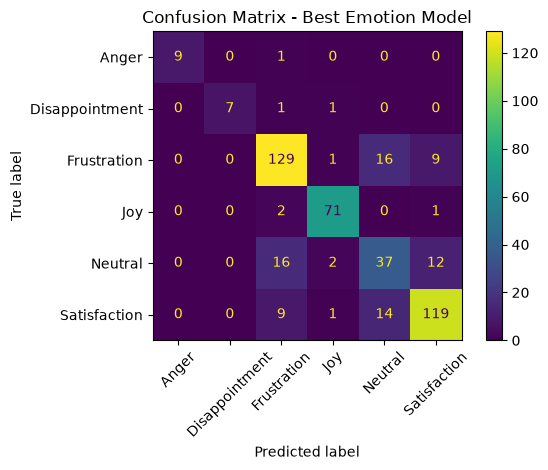

In [201]:
plt.figure(
    figsize=(9, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

disp.plot(
    xticks_rotation=45
)

plt.title(
    "Confusion Matrix - Best Emotion Model"
)

plt.tight_layout()

plt.show()

In [203]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    best_prediction,
    labels=best_model.classes_
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[  9   0   1   0   0   0]
 [  0   7   1   1   0   0]
 [  0   0 129   1  16   9]
 [  0   0   2  71   0   1]
 [  0   0  16   2  37  12]
 [  0   0   9   1  14 119]]


<Figure size 900x800 with 0 Axes>

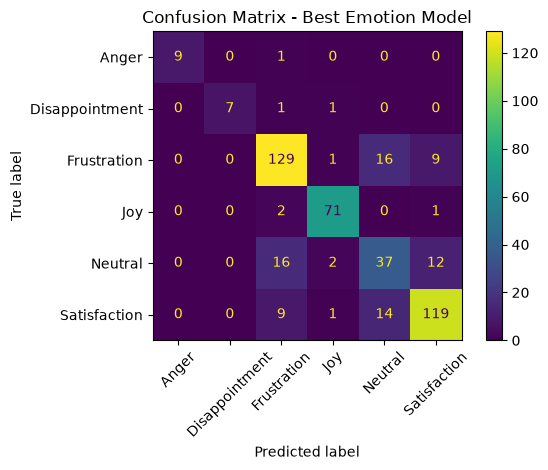

In [204]:
plt.figure(
    figsize=(9, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

disp.plot(
    xticks_rotation=45
)

plt.title(
    "Confusion Matrix - Best Emotion Model"
)

plt.tight_layout()

plt.show()

In [205]:
report = classification_report(
    y_test,
    best_prediction,
    output_dict=True,
    zero_division=0
)

emotion_performance = pd.DataFrame(
    report
).transpose()

emotion_performance

,precision,recall,f1-score,support
Anger,1.000000,0.900000,0.947368,10.000000
Disappointment,1.000000,0.777778,0.875000,9.000000
Frustration,0.816456,0.832258,0.824281,155.000000
Joy,0.934211,0.959459,0.946667,74.000000
Neutral,0.552239,0.552239,0.552239,67.000000
Satisfaction,0.843972,0.832168,0.838028,143.000000
accuracy,0.812227,0.812227,0.812227,0.812227
macro avg,0.857813,0.808984,0.830597,458.000000
weighted avg,0.813035,0.812227,0.812235,458.000000


In [206]:
emotion_performance_only = (
    emotion_performance
    .loc[
        [
            emotion
            for emotion in best_model.classes_
            if emotion in emotion_performance.index
        ]
    ]
)

emotion_performance_only

,precision,recall,f1-score,support
Anger,1.000000,0.900000,0.947368,10.0
Disappointment,1.000000,0.777778,0.875000,9.0
Frustration,0.816456,0.832258,0.824281,155.0
Joy,0.934211,0.959459,0.946667,74.0
Neutral,0.552239,0.552239,0.552239,67.0
Satisfaction,0.843972,0.832168,0.838028,143.0


In [207]:
final_emotion_pipeline = Pipeline([
    
    (
        "tfidf",
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),

    (
        "model",
        best_model
    )
])

print(
    "Final emotion pipeline created!"
)

Final emotion pipeline created!


In [208]:
final_emotion_pipeline.fit(
    X_train,
    y_train
)

print(
    "Final emotion pipeline trained successfully!"
)

Final emotion pipeline trained successfully!


In [209]:
final_test_prediction = (
    final_emotion_pipeline.predict(
        X_test
    )
)

final_accuracy = accuracy_score(
    y_test,
    final_test_prediction
)

final_f1 = f1_score(
    y_test,
    final_test_prediction,
    average="weighted",
    zero_division=0
)

print(
    "Final Pipeline Accuracy:",
    round(final_accuracy, 4)
)

print(
    "Final Pipeline F1 Score:",
    round(final_f1, 4)
)

Final Pipeline Accuracy: 0.8122
Final Pipeline F1 Score: 0.8122


In [210]:
final_test_prediction = (
    final_emotion_pipeline.predict(
        X_test
    )
)

final_accuracy = accuracy_score(
    y_test,
    final_test_prediction
)

final_f1 = f1_score(
    y_test,
    final_test_prediction,
    average="weighted",
    zero_division=0
)

print(
    "Final Pipeline Accuracy:",
    round(final_accuracy, 4)
)

print(
    "Final Pipeline F1 Score:",
    round(final_f1, 4)
)

Final Pipeline Accuracy: 0.8122
Final Pipeline F1 Score: 0.8122


In [211]:
os.makedirs(
    "models",
    exist_ok=True
)

joblib.dump(
    final_emotion_pipeline,
    "models/emotion_model.pkl"
)

print(
    "Emotion model saved successfully!"
)

print(
    "Location: models/emotion_model.pkl"
)

Emotion model saved successfully!
Location: models/emotion_model.pkl


In [212]:
model_path = "models/emotion_model.pkl"

print(
    "File exists:",
    os.path.exists(model_path)
)

print(
    "File size:",
    round(
        os.path.getsize(model_path) / 1024,
        2
    ),
    "KB"
)

File exists: True
File size: 433.9 KB


In [213]:
loaded_emotion_model = joblib.load(
    "models/emotion_model.pkl"
)

print(
    "Saved emotion model loaded successfully!"
)

Saved emotion model loaded successfully!


In [214]:
test_reviews = [

    "I love the battery life of this laptop.",

    "The battery drains very quickly and it is annoying.",

    "The display is excellent and beautiful.",

    "The laptop is extremely slow and frustrating.",

    "The product is terrible and useless."
]

for review in test_reviews:

    prediction = loaded_emotion_model.predict(
        [review]
    )[0]

    print("\nReview:", review)
    print("Predicted Emotion:", prediction)


Review: I love the battery life of this laptop.
Predicted Emotion: Joy

Review: The battery drains very quickly and it is annoying.
Predicted Emotion: Frustration

Review: The display is excellent and beautiful.
Predicted Emotion: Joy

Review: The laptop is extremely slow and frustrating.
Predicted Emotion: Frustration

Review: The product is terrible and useless.
Predicted Emotion: Anger


In [215]:
results_percentage.to_csv(
    "model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Model comparison saved!"
)

Model comparison saved!


In [216]:
X_sentiment = ml_df["Model Text"]

y_sentiment = ml_df["polarity"]

print(
    "Sentiment classes:"
)

print(
    y_sentiment.value_counts()
)

Sentiment classes:
polarity
positive    965
negative    830
neutral     448
conflict     45
Name: count, dtype: int64


In [219]:
from sklearn.model_selection import train_test_split

# Sentiment input and target
X_sentiment = ml_df["Model Text"]
y_sentiment = ml_df["polarity"]

# Train-test split
(
    X_train_sent,
    X_test_sent,
    y_train_sent,
    y_test_sent
) = train_test_split(
    X_sentiment,
    y_sentiment,
    test_size=0.20,
    random_state=42,
    stratify=y_sentiment
)

print("Sentiment data split successfully!")
print("Training samples:", len(X_train_sent))
print("Testing samples:", len(X_test_sent))

print("\nTraining sentiment distribution:")
print(y_train_sent.value_counts())

print("\nTesting sentiment distribution:")
print(y_test_sent.value_counts())

Sentiment data split successfully!
Training samples: 1830
Testing samples: 458

Training sentiment distribution:
polarity
positive    772
negative    664
neutral     358
conflict     36
Name: count, dtype: int64

Testing sentiment distribution:
polarity
positive    193
negative    166
neutral      90
conflict      9
Name: count, dtype: int64


In [220]:
sentiment_pipeline = Pipeline([

    (
        "tfidf",
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),

    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])

print(
    "Sentiment pipeline created!"
)

Sentiment pipeline created!


In [221]:
sentiment_pipeline.fit(
    X_train_sent,
    y_train_sent
)

print(
    "Sentiment model trained successfully!"
)

Sentiment model trained successfully!


In [222]:
sentiment_prediction = (
    sentiment_pipeline.predict(
        X_test_sent
    )
)

sentiment_accuracy = accuracy_score(
    y_test_sent,
    sentiment_prediction
)

sentiment_f1 = f1_score(
    y_test_sent,
    sentiment_prediction,
    average="weighted",
    zero_division=0
)

print(
    "Sentiment Accuracy:",
    round(sentiment_accuracy, 4)
)

print(
    "Sentiment F1 Score:",
    round(sentiment_f1, 4)
)

Sentiment Accuracy: 0.6856
Sentiment F1 Score: 0.6922


In [223]:
print(
    classification_report(
        y_test_sent,
        sentiment_prediction,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    conflict       0.10      0.11      0.11         9
    negative       0.70      0.70      0.70       166
     neutral       0.50      0.63      0.56        90
    positive       0.83      0.72      0.77       193

    accuracy                           0.69       458
   macro avg       0.53      0.54      0.53       458
weighted avg       0.71      0.69      0.69       458



In [224]:
joblib.dump(
    sentiment_pipeline,
    "models/sentiment_model.pkl"
)

print(
    "Sentiment model saved successfully!"
)

print(
    "Location: models/sentiment_model.pkl"
)

Sentiment model saved successfully!
Location: models/sentiment_model.pkl


In [225]:
print("=" * 60)
print("MODEL FILE VERIFICATION")
print("=" * 60)

print(
    "Emotion model:",
    os.path.exists(
        "models/emotion_model.pkl"
    )
)

print(
    "Sentiment model:",
    os.path.exists(
        "models/sentiment_model.pkl"
    )
)

MODEL FILE VERIFICATION
Emotion model: True
Sentiment model: True


In [226]:
results_percentage

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,76.64,77.70,76.64,77.04
1,Multinomial Naive Bayes,69.00,71.19,69.00,63.88
2,Linear SVM,81.22,81.30,81.22,81.22


In [227]:
print(
    classification_report(
        y_test,
        best_prediction,
        zero_division=0
    )
)

                precision    recall  f1-score   support

         Anger       1.00      0.90      0.95        10
Disappointment       1.00      0.78      0.88         9
   Frustration       0.82      0.83      0.82       155
           Joy       0.93      0.96      0.95        74
       Neutral       0.55      0.55      0.55        67
  Satisfaction       0.84      0.83      0.84       143

      accuracy                           0.81       458
     macro avg       0.86      0.81      0.83       458
  weighted avg       0.81      0.81      0.81       458



In [228]:
# ============================================
# PHASE 9: FINAL PREDICTION SYSTEM
# ============================================

import os
import re
import joblib
import pandas as pd

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [229]:
# Load trained models

emotion_model = joblib.load(
    "models/emotion_model.pkl"
)

sentiment_model = joblib.load(
    "models/sentiment_model.pkl"
)

print("Emotion model loaded successfully!")
print("Sentiment model loaded successfully!")

Emotion model loaded successfully!
Sentiment model loaded successfully!


Emotion model loaded successfully!
Sentiment model loaded successfully!


In [231]:
print("Emotion classes:")
print(emotion_model.classes_)

print("\nSentiment classes:")
print(sentiment_model.classes_)

Emotion classes:
['Anger' 'Disappointment' 'Frustration' 'Joy' 'Neutral' 'Satisfaction']

Sentiment classes:
['conflict' 'negative' 'neutral' 'positive']


In [232]:
def prepare_prediction_text(text):

    text = str(text)

    # Lowercase
    text = text.lower()

    # Remove special characters
    text = re.sub(
        r"[^a-zA-Z\s]",
        " ",
        text
    )

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    # Tokenization
    tokens = word_tokenize(text)

    processed_tokens = []

    for word in tokens:

        if word not in stop_words:

            if len(word) > 1:

                lemma = lemmatizer.lemmatize(word)

                processed_tokens.append(
                    lemma
                )

    return " ".join(processed_tokens)

In [233]:
def get_aspect_category(aspect):

    aspect = str(aspect).lower().strip()

    for category, keywords in aspect_categories.items():

        for keyword in keywords:

            if keyword in aspect:

                return category

    return "Other"

In [234]:
def predict_aspect_emotion(
    review,
    aspect
):

    # Create model input
    model_text = create_model_text(
        review,
        aspect
    )

    # Predict sentiment
    sentiment = sentiment_model.predict(
        [model_text]
    )[0]

    # Predict emotion
    emotion = emotion_model.predict(
        [model_text]
    )[0]

    # Aspect category
    category = get_aspect_category(
        aspect
    )

    return {
        "Aspect": aspect,
        "Aspect Category": category,
        "Sentiment": sentiment,
        "Emotion": emotion
    }

In [236]:
result = predict_aspect_emotion(
    "The battery drains very quickly and is annoying.",
    "battery"
)

result

NameError: name 'create_model_text' is not defined

In [237]:
import re
import nltk

from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Download resources if needed
nltk.download("punkt")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("stopwords")

from nltk.corpus import stopwords

stop_words = set(
    stopwords.words("english")
)

lemmatizer = WordNetLemmatizer()

print("NLP tools loaded!")

NLP tools loaded!


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ritik\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ritik\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\ritik\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ritik\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [238]:
def prepare_prediction_text(text):

    text = str(text)

    # Lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(
        r"[^a-zA-Z\s]",
        " ",
        text
    )

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    # Tokenize
    tokens = word_tokenize(text)

    processed_tokens = []

    for word in tokens:

        if word not in stop_words:

            if len(word) > 1:

                word = lemmatizer.lemmatize(word)

                processed_tokens.append(word)

    return " ".join(processed_tokens)

In [239]:
prepare_prediction_text(
    "The battery drains very quickly!"
)

'battery drain quickly'

In [240]:
def create_model_text(review, aspect):

    processed_review = prepare_prediction_text(
        review
    )

    processed_aspect = prepare_prediction_text(
        aspect
    )

    model_text = (
        processed_review
        + " aspect "
        + processed_aspect
    )

    return model_text

In [241]:
test_text = create_model_text(
    "The battery drains very quickly",
    "battery"
)

print(test_text)

battery drain quickly aspect battery


In [242]:
test_text = create_model_text(
    "The battery drains very quickly",
    "battery"
)

print(test_text)

battery drain quickly aspect battery


In [243]:
test_cases = [

    (
        "The battery lasts all day and I love it.",
        "battery"
    ),

    (
        "The screen is beautiful and very bright.",
        "display"
    ),

    (
        "The laptop is very slow and frustrating.",
        "performance"
    ),

    (
        "The keyboard feels comfortable and works well.",
        "keyboard"
    ),

    (
        "The speakers sound terrible.",
        "sound"
    )
]

for review, aspect in test_cases:

    result = predict_aspect_emotion(
        review,
        aspect
    )

    print("\nReview:", review)
    print("Aspect:", result["Aspect"])
    print("Category:", result["Aspect Category"])
    print("Sentiment:", result["Sentiment"])
    print("Emotion:", result["Emotion"])
    print("-" * 60)


Review: The battery lasts all day and I love it.
Aspect: battery
Category: Battery
Sentiment: positive
Emotion: Joy
------------------------------------------------------------

Review: The screen is beautiful and very bright.
Aspect: display
Category: Display
Sentiment: positive
Emotion: Satisfaction
------------------------------------------------------------

Review: The laptop is very slow and frustrating.
Aspect: performance
Category: Performance
Sentiment: negative
Emotion: Frustration
------------------------------------------------------------

Review: The keyboard feels comfortable and works well.
Aspect: keyboard
Category: Keyboard
Sentiment: positive
Emotion: Satisfaction
------------------------------------------------------------

Review: The speakers sound terrible.
Aspect: sound
Category: Sound
Sentiment: negative
Emotion: Frustration
------------------------------------------------------------


In [244]:
review = (
    "The display is beautiful but "
    "the battery drains very quickly."
)

results = []

for aspect in ["display", "battery"]:

    result = predict_aspect_emotion(
        review,
        aspect
    )

    results.append(result)

final_result = pd.DataFrame(
    results
)

final_result

,Aspect,Aspect Category,Sentiment,Emotion
0,display,Display,positive,Satisfaction
1,battery,Battery,negative,Frustration


In [245]:
def detect_aspects(review):

    review_lower = str(review).lower()

    detected = []

    for category, keywords in aspect_categories.items():

        for keyword in keywords:

            if keyword in review_lower:

                detected.append({
                    "Aspect": keyword,
                    "Aspect Category": category
                })

                break

    return detected

In [246]:
review = (
    "The display is beautiful but "
    "the battery drains very quickly. "
    "The keyboard is also comfortable."
)

detected_aspects = detect_aspects(
    review
)

detected_aspects

[{'Aspect': 'battery', 'Aspect Category': 'Battery'},
 {'Aspect': 'display', 'Aspect Category': 'Display'},
 {'Aspect': 'keyboard', 'Aspect Category': 'Keyboard'}]

In [247]:
review = (
    "The display is beautiful but "
    "the battery drains very quickly. "
    "The keyboard is also comfortable."
)

detected_aspects = detect_aspects(
    review
)

detected_aspects

[{'Aspect': 'battery', 'Aspect Category': 'Battery'},
 {'Aspect': 'display', 'Aspect Category': 'Display'},
 {'Aspect': 'keyboard', 'Aspect Category': 'Keyboard'}]

In [248]:
def analyze_review(review):

    detected_aspects = detect_aspects(
        review
    )

    results = []

    for item in detected_aspects:

        aspect = item["Aspect"]

        result = predict_aspect_emotion(
            review,
            aspect
        )

        results.append(result)

    if len(results) == 0:

        return pd.DataFrame(
            columns=[
                "Aspect",
                "Aspect Category",
                "Sentiment",
                "Emotion"
            ]
        )

    return pd.DataFrame(results)

In [249]:
review = """
The display is beautiful but the battery
drains very quickly. The keyboard is
comfortable and the speakers are terrible.
"""

analysis_result = analyze_review(
    review
)

analysis_result

,Aspect,Aspect Category,Sentiment,Emotion
0,battery,Battery,negative,Anger
1,display,Display,negative,Anger
2,keyboard,Keyboard,negative,Anger
3,speaker,Sound,negative,Anger


In [251]:
emotion_score = {

    "Neutral": 0,

    "Satisfaction": 1,

    "Joy": 2,

    "Disappointment": -1,

    "Frustration": -2,

    "Anger": -3
}

In [252]:
def analyze_review(review):

    detected_aspects = detect_aspects(
        review
    )

    results = []

    for item in detected_aspects:

        aspect = item["Aspect"]

        result = predict_aspect_emotion(
            review,
            aspect
        )

        result["Emotion Score"] = (
            emotion_score.get(
                result["Emotion"],
                0
            )
        )

        results.append(result)

    if len(results) == 0:

        return pd.DataFrame(
            columns=[
                "Aspect",
                "Aspect Category",
                "Sentiment",
                "Emotion",
                "Emotion Score"
            ]
        )

    return pd.DataFrame(results)

In [253]:
review = """
The display is amazing but the battery
is terrible. The keyboard is good.
"""

result = analyze_review(
    review
)

result

,Aspect,Aspect Category,Sentiment,Emotion,Emotion Score
0,battery,Battery,positive,Satisfaction,1
1,display,Display,positive,Satisfaction,1
2,keyboard,Keyboard,positive,Satisfaction,1


In [254]:
if len(result) > 0:

    overall_score = result[
        "Emotion Score"
    ].mean()

    print(
        "Overall Emotion Score:",
        round(overall_score, 2)
    )

Overall Emotion Score: 1.0


In [255]:
if len(result) > 0:

    overall_score = result[
        "Emotion Score"
    ].mean()

    print(
        "Overall Emotion Score:",
        round(overall_score, 2)
    )

Overall Emotion Score: 1.0


In [256]:
interpret_emotion_score(
    overall_score
)

NameError: name 'interpret_emotion_score' is not defined

In [257]:
def complete_product_analysis(review):

    result = analyze_review(
        review
    )

    if len(result) == 0:

        return {
            "results": result,
            "overall_score": 0,
            "overall_emotion": "Neutral / Mixed"
        }

    overall_score = result[
        "Emotion Score"
    ].mean()

    overall_emotion = (
        interpret_emotion_score(
            overall_score
        )
    )

    return {
        "results": result,
        "overall_score": round(
            overall_score,
            2
        ),
        "overall_emotion": overall_emotion
    }

In [260]:
review = """
I love the display because it is bright and beautiful.
However, the battery drains very quickly and the
laptop becomes hot. The keyboard feels comfortable.
"""

final_analysis = complete_product_analysis(
    review
)

print(
    "Overall Emotion:",
    final_analysis["overall_emotion"]
)

print(
    "Overall Score:",
    final_analysis["overall_score"]
)

print("\nAspect-Level Analysis:")

display(
    final_analysis["results"]
)

NameError: name 'interpret_emotion_score' is not defined

In [261]:
# ============================================
# EMOTION SCORE INTERPRETATION
# ============================================

emotion_score = {
    "Neutral": 0,
    "Satisfaction": 1,
    "Joy": 2,
    "Disappointment": -1,
    "Frustration": -2,
    "Anger": -3
}


def interpret_emotion_score(score):

    if score >= 1.5:
        return "Highly Positive"

    elif score >= 0.5:
        return "Positive"

    elif score > -0.5:
        return "Neutral / Mixed"

    elif score > -1.5:
        return "Negative"

    else:
        return "Highly Negative"


print("Emotion score function created successfully!")

Emotion score function created successfully!


In [262]:
print(interpret_emotion_score(2))
print(interpret_emotion_score(1))
print(interpret_emotion_score(0))
print(interpret_emotion_score(-2))
print(interpret_emotion_score(-3))

Highly Positive
Positive
Neutral / Mixed
Highly Negative
Highly Negative


In [263]:
review = """
I love the display because it is bright and beautiful.
However, the battery drains very quickly and the
laptop becomes hot. The keyboard feels comfortable.
"""

final_analysis = complete_product_analysis(
    review
)

print(
    "Overall Emotion:",
    final_analysis["overall_emotion"]
)

print(
    "Overall Score:",
    final_analysis["overall_score"]
)

display(
    final_analysis["results"]
)

Overall Emotion: Highly Positive
Overall Score: 2.0


,Aspect,Aspect Category,Sentiment,Emotion,Emotion Score
0,battery,Battery,positive,Joy,2
1,display,Display,positive,Joy,2
2,keyboard,Keyboard,positive,Joy,2


In [264]:
def complete_product_analysis(review):

    result = analyze_review(review)

    if len(result) == 0:

        return {
            "results": result,
            "overall_score": 0,
            "overall_emotion": "Neutral / Mixed"
        }

    overall_score = result["Emotion Score"].mean()

    overall_emotion = interpret_emotion_score(
        overall_score
    )

    return {
        "results": result,
        "overall_score": round(overall_score, 2),
        "overall_emotion": overall_emotion
    }

print("Complete analysis function created!")

Complete analysis function created!
